<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-09/lab-047-quantum-reservoir-computing.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 047 <br>
<hr/>

# Lab 047 — Quantum reservoir computing

A register of $N$ interacting qubits driven by an input signal is a dynamical system with a very large state space. Its state $\hat\rho_k$ after $k$ inputs is a $2^N\times2^N$ density matrix fixed by $4^N-1$ real numbers. Quantum reservoir computing (QRC) uses such a register as the reservoir of an echo state network (ESN). The input enters one qubit, the register evolves under a fixed Hamiltonian, a set of expectation values is read out as features, and only a linear readout of these features is fitted [K. Fujii, K. Nakajima, Phys. Rev. Appl. **8**, 024030 (2017), [doi:10.1103/PhysRevApplied.8.024030](https://doi.org/10.1103/PhysRevApplied.8.024030)]. Whether the register is a useful reservoir depends on its dynamics. A register that spreads the input over all qubits and forgets its initial state behaves differently from one in which the input stays where it entered, and both differ from one that never forgets.

We start with the physics of the reservoir, a transverse-field Ising model on a fully connected network of spins with random couplings and random local fields. Its dynamics is chaotic in some parameter regions and close to integrable in others, and we characterise it by its conserved quantities and by the statistics of its energy levels, measured by the mean level-spacing ratio $\langle r\rangle$. This separates the ergodic, many-body localised and spin-glass regimes of the model, following R. Martínez-Peña, G. L. Giorgi, J. Nokkala, M. C. Soriano, R. Zambrini, Phys. Rev. Lett. **127**, 100502 (2021), [doi:10.1103/PhysRevLett.127.100502](https://doi.org/10.1103/PhysRevLett.127.100502). We then write one reservoir step as a linear map on density matrices and check its properties, and we measure how fast two copies of the register driven by the same inputs forget their different initial states. The memory capacity and a nonlinear benchmark task are scanned across the regimes and compared with a classical ESN with as many neurons as the quantum reservoir has features. A forecasting example on the Santa Fe laser data follows. The notebook closes with the measurement of the features, the restart and online protocols, the back-action of a weak measurement and the effect of a finite number of shots.

The register has $N=6$ qubits, so every density matrix is a $64\times64$ matrix and the whole notebook runs on a CPU. All results refer to this small size, and finite-size effects are discussed where they matter. The implementation uses JAX in double precision, and the ridge regression is checked against scikit-learn.

> **How to run this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. The first code cell sets `JAX_PLATFORMS=cpu`. The whole notebook runs in five to twenty minutes on a multi-core CPU, depending on its load.
> 2. `jax`, `scikit-learn` and `matplotlib` are pre-installed in Colab. The Santa Fe laser data file has to be uploaded to Colab, and the cell that loads it adjusted to its location.
> 3. Run the cells *in order*. Later cells use variables defined earlier.

In [ ]:
# data files of this notebook, downloaded from the course repository if they are not in ./data
import os, urllib.request
os.makedirs("data", exist_ok=True)
for name in ['santafe_laser.txt']:
    if not os.path.exists(f"data/{name}"):
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/main/notebooks/lecture-09/data/{name}", f"data/{name}")

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)

import json, time
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyBboxPatch, FancyArrowPatch

import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)   # all computations of this notebook in float64 and complex128
import sklearn
from sklearn.linear_model import Ridge as SkRidge

# common style of the notebook figures
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
# slide figures are drawn at their printed size (5.5 in = full width of a slide), so these are true font sizes
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 11,
            "ytick.labelsize": 11, "legend.fontsize": 11, "lines.linewidth": 1.4, "figure.dpi": 150}

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
# the three dynamical regimes of the spin network studied below, with their parameters (field h and disorder strength D, stored under the key W, in units of J_s)
REG = {"ergodic": dict(h=10.0, W=0.0, color=UJBlue, ls="-"),
       "spin glass": dict(h=0.01, W=0.0, color=DSOrange, ls="--"),
       "localised": dict(h=1.0, W=100.0, color="#7B4FA0", ls="-.")}
ESN_COLOR = "#2A9D8F"

OUT = "figures"
os.makedirs(OUT, exist_ok=True)
def save(fig, name):
    # slide figures are created at their printed size and saved as PDF (slides) and PNG
    for ext in ("pdf", "png"):
        fig.savefig(f"{OUT}/{name}.{ext}", dpi=300, bbox_inches="tight", pad_inches=0.02)

nums = {}                 # every number a slide may need, written to the numbers file at the end
t_start = time.time()
print("jax", jax.__version__, "| scikit-learn", sklearn.__version__)

jax 0.11.0 | scikit-learn 1.6.1


<hr/>
## 1. Transverse-field Ising spin network

The reservoir is a network of $N$ qubits in which every pair is coupled, with the Hamiltonian
$$
\hat H=\sum_{i<j}J_{ij}\,\hat X_i\hat X_j+\frac12\sum_{i=1}^{N}\big(h+D_i\big)\hat Z_i .
$$
Here $\hat X_i$, $\hat Y_i$, $\hat Z_i$ are the Pauli matrices
$$
\hat X=\begin{pmatrix}0&1\\1&0\end{pmatrix},\qquad \hat Y=\begin{pmatrix}0&-i\\i&0\end{pmatrix},\qquad \hat Z=\begin{pmatrix}1&0\\0&-1\end{pmatrix}
$$
acting on qubit $i$, and $|0\rangle$, $|1\rangle$ are the eigenstates of $\hat Z$ with eigenvalues $z_i=+1$ and $z_i=-1$. The couplings $J_{ij}$ are drawn once from the uniform distribution on $[-J_s/2,J_s/2]$, and each term $\hat X_i\hat X_j$ flips the spins $i$ and $j$ together. The coupling scale $J_s$ sets the unit of energy and of inverse time. The transverse field $h$ splits the two states of every qubit by the same energy $h$. The local disorder $D_i$, drawn from the uniform distribution on $[-D,D]$, gives every qubit its own splitting, so that a flip-flop $|\dots0_i\dots1_j\dots\rangle\to|\dots1_i\dots0_j\dots\rangle$ produced by $\hat X_i\hat X_j$ costs the energy $|D_i-D_j|$. This is the model of Martínez-Peña *et al.*, which goes back to the disordered spin ensembles of Fujii and Nakajima.

Two symmetries matter for what follows. The matrix of $\hat H$ in the basis of the states $|z_1\dots z_N\rangle$ is real, so $\hat H$ is invariant under time reversal. Each term $\hat X_i\hat X_j$ flips two spins, so $\hat H$ commutes with the parity $\hat\Pi=\hat Z_1\hat Z_2\cdots \hat Z_N$, and its spectrum splits into an even and an odd sector of $2^{N-1}$ levels each. The level statistics below are computed in the even sector.

The implementation builds $\hat H$ without Kronecker products. In the computational basis $\hat X_i\hat X_j$ is a permutation matrix that maps every basis state to the state with bits $i$ and $j$ flipped, and the field term is diagonal with entries $\frac12\sum_i(h+D_i)z_i$. We check the result against the Kronecker-product construction for four qubits and verify that $\hat H$ commutes with $\hat\Pi$.

In [2]:
PAULI = {"I": np.eye(2, dtype=complex), "X": np.array([[0, 1], [1, 0]], complex),
         "Y": np.array([[0, -1j], [1j, 0]]), "Z": np.diag([1.0 + 0j, -1.0])}
def pauli_string(n, ops):
    # tensor product with the Pauli matrix ops[i] on qubit i and the identity elsewhere
    out = np.ones((1, 1), complex)
    for i in range(n):
        out = np.kron(out, PAULI[ops.get(i, "I")])
    return out

N = 6                    # qubits of the reservoir
DIM = 2 ** N             # dimension of the Hilbert space
JS, DT = 1.0, 10.0       # coupling scale J_s (unit of energy) and time between two inputs, J_s * dt = 10

def basis_spins(n):
    # z_i = +1 for |0> and -1 for |1> in every computational basis state; qubit 1 is the most significant bit
    idx = np.arange(2 ** n)
    return idx, 1 - 2 * ((idx[:, None] >> (n - 1 - np.arange(n))[None, :]) & 1)

def hamiltonian(n, h, W, key):
    """H = sum_{i<j} J_ij X_i X_j + 1/2 sum_i (h + D_i) Z_i,  J_ij ~ U[-J_s/2, J_s/2],  D_i ~ U[-W, W]."""
    idx, z = basis_spins(n)
    pairs = [(i, j) for i in range(n) for j in range(i + 1, n)]
    # X_i X_j flips the bits of qubits i and j, so it has one nonzero element in every row
    flip = np.array([idx ^ ((1 << (n - 1 - i)) | (1 << (n - 1 - j))) for i, j in pairs])
    k_J, k_D = jax.random.split(key)
    J = jax.random.uniform(k_J, (len(pairs),), minval=-JS / 2, maxval=JS / 2)
    D = jax.random.uniform(k_D, (n,), minval=-W, maxval=W)
    H = jnp.zeros((2 ** n, 2 ** n)).at[np.tile(idx, len(pairs)), flip.ravel()].add(jnp.repeat(J, 2 ** n))
    return H + jnp.diag(0.5 * (jnp.asarray(z, jnp.float64) @ (h + D)))

# check against the Kronecker-product construction and the parity symmetry, for n = 4 qubits
n_chk, key_chk = 4, jax.random.key(3)
H_fast = np.asarray(hamiltonian(n_chk, 0.7, 0.4, key_chk))
k_J, k_D = jax.random.split(key_chk)
pairs = [(i, j) for i in range(n_chk) for j in range(i + 1, n_chk)]
J_chk = np.asarray(jax.random.uniform(k_J, (len(pairs),), minval=-JS / 2, maxval=JS / 2))
D_chk = np.asarray(jax.random.uniform(k_D, (n_chk,), minval=-0.4, maxval=0.4))
H_kron = sum(J_chk[p] * pauli_string(n_chk, {i: "X", j: "X"}) for p, (i, j) in enumerate(pairs))
H_kron = H_kron + sum(0.5 * (0.7 + D_chk[i]) * pauli_string(n_chk, {i: "Z"}) for i in range(n_chk))
parity = pauli_string(n_chk, {i: "Z" for i in range(n_chk)})
print("max |H - H_kron| =", np.abs(H_fast - H_kron).max(), "| max |[H, Z_1...Z_n]| =", np.abs(H_fast @ parity - parity @ H_fast).max())

max |H - H_kron| = 0.0 | max |[H, Z_1...Z_n]| = 0.0


The drawing below shows the register and one step of its use as a reservoir. Qubit 1 (orange) receives the input $s_k$ by a reset of its state, all qubits evolve together under $\hat H$ for a time $\Delta t$, a set of Pauli expectation values is measured, and a linear readout of these values gives the output $\tilde y_k$. The state of qubits $2,\dots,N$ is kept from one step to the next and carries the memory of earlier inputs. The formulas of each stage follow in the text below.

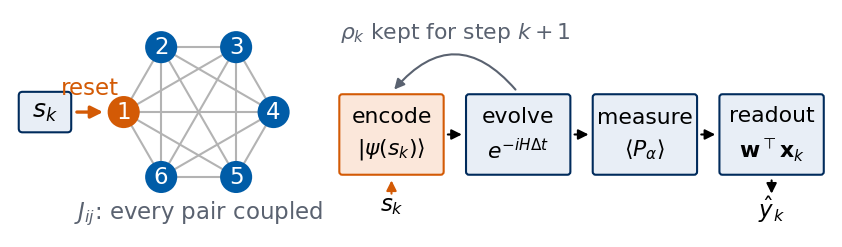

In [3]:
def draw_network(ax, n=N):
    # all-to-all couplings J_ij (grey lines), input qubit 1 in orange, the other qubits in blue
    ang = np.pi - 2 * np.pi * np.arange(n) / n
    xy = np.c_[np.cos(ang), np.sin(ang)]
    for i in range(n):
        for j in range(i + 1, n):
            ax.plot(*xy[[i, j]].T, color="0.7", lw=1.0, zorder=1)
    for i in range(n):
        ax.add_patch(Circle(xy[i], 0.2, color=DSOrange if i == 0 else UJBlue, zorder=2))
        ax.text(*xy[i], str(i + 1), color="white", ha="center", va="center", fontsize=11, zorder=3)
    ax.add_patch(FancyBboxPatch((-2.35, -0.22), 0.6, 0.44, boxstyle="round,pad=0.05", fc="#E8EEF6", ec=UJNavy))
    ax.text(-2.05, 0, "$s_k$", ha="center", va="center", fontsize=12)
    ax.add_patch(FancyArrowPatch((-1.68, 0), (-1.22, 0), arrowstyle="-|>", mutation_scale=12, color=DSOrange, lw=1.6))
    ax.text(-1.45, 0.17, "reset", ha="center", va="bottom", fontsize=11, color=DSOrange)
    ax.text(0, -1.42, r"$J_{ij}$: every pair coupled", ha="center", fontsize=11, color=UJGray)
    ax.set_xlim(-2.45, 1.3); ax.set_ylim(-1.6, 1.3); ax.set_aspect("equal"); ax.axis("off")

def draw_step(ax):
    # one reservoir step: encode s_k into qubit 1, evolve all qubits, measure Pauli strings, linear readout
    boxes = [(0.75, "encode\n" + r"$|\psi(s_k)\rangle$", True), (2.45, "evolve\n" + r"$e^{-iH\Delta t}$", False),
             (4.15, "measure\n" + r"$\langle \hat P_\alpha\rangle$", False), (5.85, "readout\n" + r"$\mathbf{w}^{\top}\mathbf{x}_k$", False)]
    for i, (x, t, enc) in enumerate(boxes):
        ax.add_patch(FancyBboxPatch((x - 0.66, -0.5), 1.32, 1.0, boxstyle="round,pad=0.04",
                                    fc="#FBE7DA" if enc else "#E8EEF6", ec=DSOrange if enc else UJNavy))
        ax.text(x, 0, t, ha="center", va="center", fontsize=10.5, linespacing=1.5)
        if i:
            ax.add_patch(FancyArrowPatch((boxes[i - 1][0] + 0.7, 0), (x - 0.7, 0), arrowstyle="-|>", mutation_scale=10, color="k"))
    ax.text(0.75, -0.8, "$s_k$", ha="center", va="top", fontsize=11)
    ax.add_patch(FancyArrowPatch((0.75, -0.85), (0.75, -0.56), arrowstyle="-|>", mutation_scale=10, color=DSOrange))
    ax.text(5.85, -0.8, r"$\tilde y_k$", ha="center", va="top", fontsize=11)
    ax.add_patch(FancyArrowPatch((5.85, -0.56), (5.85, -0.85), arrowstyle="-|>", mutation_scale=10, color="k"))
    ax.add_patch(FancyArrowPatch((2.45, 0.56), (0.75, 0.56), connectionstyle="arc3,rad=0.6", arrowstyle="-|>",
                                 mutation_scale=10, color=UJGray))
    ax.text(1.6, 1.2, r"$\hat\rho_k$ kept for step $k+1$", ha="center", va="bottom", fontsize=10.5, color=UJGray)
    ax.set_xlim(0.0, 6.6); ax.set_ylim(-1.3, 1.6); ax.set_aspect("equal"); ax.axis("off")

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 1.9), gridspec_kw={"width_ratios": [1.0, 1.75]}, layout="constrained")
    draw_network(axs[0]); draw_step(axs[1])
    save(fig, "fig_lab047_spin_network"); plt.show()

<hr/>
## 2. Quantum chaos and level statistics

In a chaotic quantum system information written into one qubit spreads over the whole register. This process is called scrambling. The expectation values of operators on the qubit where the information entered lose it, and it becomes encoded in many-body correlations among all qubits. A chaotic register therefore forgets its initial state, and as a reservoir it mixes each input into all features. In an integrable system the dynamics splits into sectors labelled by the values of conserved quantities. Information carried by a conserved quantity stays in its sector for all times and is neither spread nor forgotten.

The energy spectrum is the fingerprint of these two behaviours. Independent sectors superpose uncorrelated spectra, whose levels behave like independent random numbers (Poisson statistics). The levels of a single chaotic block repel each other like the eigenvalues of a random matrix (Wigner–Dyson statistics). We first show the conserved quantities of the spin network and the fate of a local imprint, and then measure the level statistics by the mean level-spacing ratio $\langle r\rangle$ over the plane of field and disorder.

### Conserved quantities and scrambling

An operator $\hat Q$ is conserved when it commutes with the Hamiltonian, since $\frac{d}{dt}\langle \hat Q\rangle=i\langle[\hat H,\hat Q]\rangle$ in units with $\hbar=1$. The energy and the parity $\hat\Pi$ are conserved for all $h$ and $D$. An integrable system has extensively many independent conserved quantities, a number that grows with $N$, while a chaotic system conserves only the energy and a few symmetries. At $h=D=0$ the spin network is integrable, because every $\hat X_j$ commutes with every coupling $\hat X_i\hat X_k$, and the $N$ operators $\hat X_j$ are conserved. A small field breaks this weakly, $[\hat H,\hat X_j]=i(h+D_j)\hat Y_j$. At large disorder each $\hat Z_i$ is nearly conserved, because every flip-flop costs an energy of order $D$, far larger than the couplings. The next cell computes $\max_j\|[\hat H,\hat X_j]\|$, the largest singular value of the commutator, and $\|[\hat H,\hat\Pi]\|$ for one draw of six qubits at $h=D=0$ and at the three parameter points of the study.

In [4]:
# largest commutators with H for one draw of N = 6 qubits: the operators X_j, and the parity Z_1 Z_2 ... Z_N
def comm_norm(H, P):
    # largest singular value of [H, P] = HP - PH
    return float(np.linalg.norm(H @ P - P @ H, 2))

key_c = jax.random.key(50)
X_ops = [pauli_string(N, {j: "X"}) for j in range(N)]
Z_ops = [pauli_string(N, {j: "Z"}) for j in range(N)]
PARITY = pauli_string(N, {j: "Z" for j in range(N)})
comm = {}
for name, (h, W) in {"h = D = 0": (0.0, 0.0), "spin glass": (REG["spin glass"]["h"], 0.0),
                     "ergodic": (REG["ergodic"]["h"], 0.0), "localised": (REG["localised"]["h"], REG["localised"]["W"])}.items():
    H = np.asarray(hamiltonian(N, h, W, key_c))
    comm[name] = dict(X=max(comm_norm(H, P) for P in X_ops), parity=comm_norm(H, PARITY))
    print(f"{name:10s} (h = {h:g}, D = {W:g}): max_j ||[H, X_j]|| = {comm[name]['X']:.2g}, ||[H, parity]|| = {comm[name]['parity']:.0f}")
nums["commutators"] = comm

h = D = 0  (h = 0, D = 0): max_j ||[H, X_j]|| = 0, ||[H, parity]|| = 0
spin glass (h = 0.01, D = 0): max_j ||[H, X_j]|| = 0.01, ||[H, parity]|| = 0


ergodic    (h = 10, D = 0): max_j ||[H, X_j]|| = 10, ||[H, parity]|| = 0
localised  (h = 1, D = 100): max_j ||[H, X_j]|| = 87, ||[H, parity]|| = 0


The commutators with $\hat X_j$ vanish at $h=D=0$, are $0.01J_s$ at the spin-glass point and have the size of the field, $10J_s$ and $87J_s$, at the ergodic and localised points. The parity commutes with $\hat H$ at every point. A commutator only bounds the rate of change, so we follow an imprint directly. Qubit 1 is flipped in the $\hat Z$ basis, the state $|1\,0\,0\,0\,0\,0\rangle$, or in the $\hat X$ basis, the state $|{-}\,{+}\,{+}\,{+}\,{+}\,{+}\rangle$ with $\hat X|\pm\rangle=\pm|\pm\rangle$, and the register evolves under $\hat H$ alone. The figure shows $\langle \hat Z_1(t)\rangle$ and $\langle \hat X_1(t)\rangle$, averaged over 30 draws of the couplings, against the time in units of $1/J_s$. The dotted line marks the time $\Delta t$ between two inputs of the reservoir.

ergodic    mean over J_s t = 100..1000: <Z_1> = +0.38 (start -1), <X_1> = +0.00 (start -1)
spin glass mean over J_s t = 100..1000: <Z_1> = -0.01 (start -1), <X_1> = -1.00 (start -1)
localised  mean over J_s t = 100..1000: <Z_1> = -0.99 (start -1), <X_1> = -0.00 (start -1)


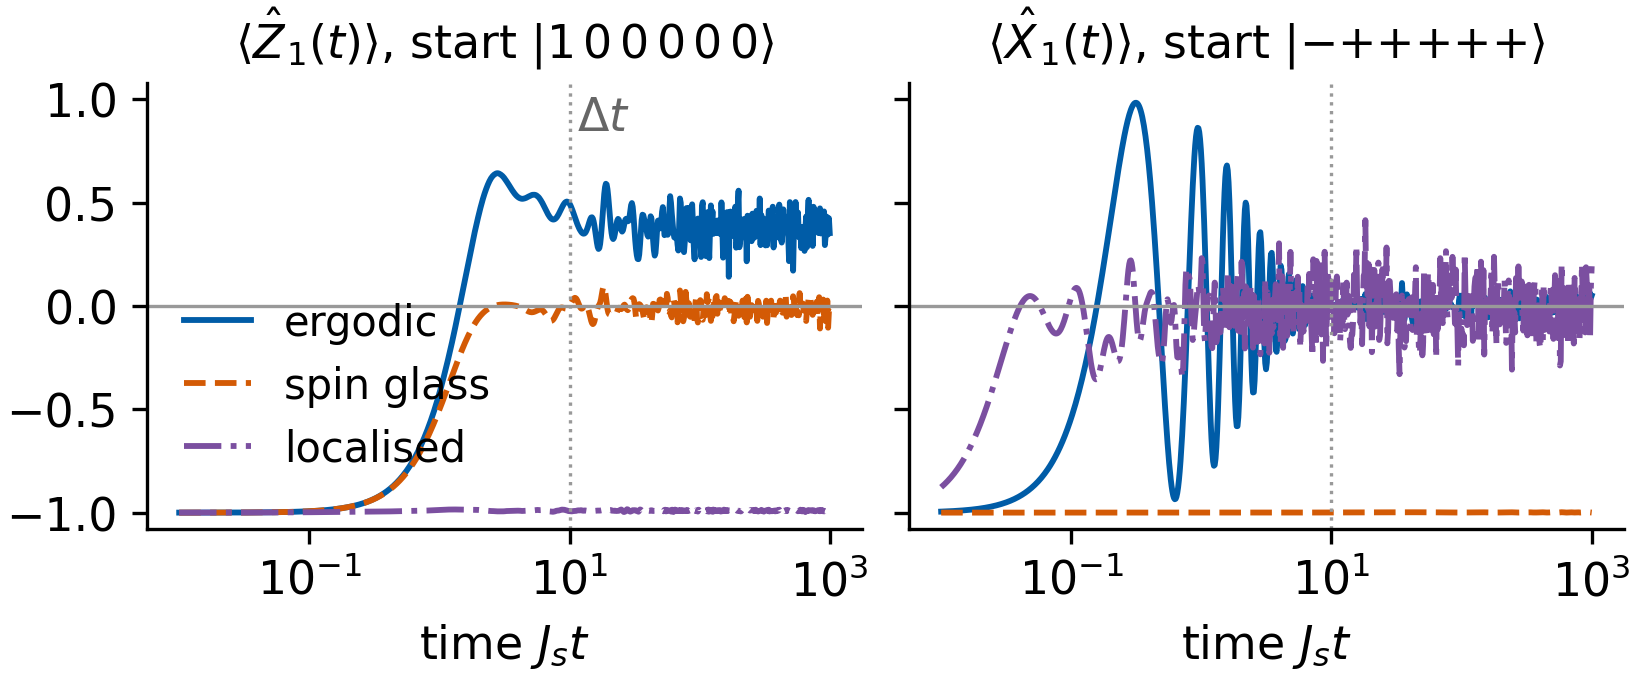

In [5]:
# a mark on qubit 1 and its fate under H alone: <Z_1(t)> from |1 0 0 0 0 0>, <X_1(t)> from |- + + + + +>
def evolve_expectation(H, psi0, O, t):
    # <psi(t)| O |psi(t)> with psi(t) = exp(-i H t) psi0, from the eigendecomposition of H
    E, V = np.linalg.eigh(H)
    c = V.T @ psi0
    psi_t = (V[None] * (np.exp(-1j * np.outer(t, E)) * c)[:, None, :]).sum(-1)     # (times, dim)
    return np.real(np.einsum("ti,ij,tj->t", psi_t.conj(), O, psi_t))

def product_state(vecs):
    out = np.ones(1, complex)
    for v in vecs:
        out = np.kron(out, v)
    return out
up, down = np.array([1, 0], complex), np.array([0, 1], complex)
plus, minus = np.array([1, 1], complex) / np.sqrt(2), np.array([1, -1], complex) / np.sqrt(2)
psi_Z = product_state([down] + [up] * (N - 1))           # qubit 1 flipped in the Z basis
psi_X = product_state([minus] + [plus] * (N - 1))        # qubit 1 flipped in the X basis
T_EV = np.logspace(-2, 3, 800)                           # J_s t from 0.01 to 1000, the reservoir step is J_s dt = 10
N_REAL_EV = 30
keys_ev = jax.random.split(jax.random.key(60), N_REAL_EV)
trace = {}
for name, p in REG.items():
    Hs = [np.asarray(hamiltonian(N, p["h"], p["W"], k)) for k in keys_ev]
    trace[name] = dict(Z=np.mean([evolve_expectation(H, psi_Z, Z_ops[0], T_EV) for H in Hs], axis=0),
                       X=np.mean([evolve_expectation(H, psi_X, X_ops[0], T_EV) for H in Hs], axis=0))
late = T_EV >= 100                                        # time average over J_s t = 100 ... 1000
nums["mark"] = {name: dict(Z_late=float(tr["Z"][late].mean()), X_late=float(tr["X"][late].mean())) for name, tr in trace.items()}
for name, v in nums["mark"].items():
    print(f"{name:10s} mean over J_s t = 100..1000: <Z_1> = {v['Z_late']:+.2f} (start -1), <X_1> = {v['X_late']:+.2f} (start -1)")

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.3), layout="constrained", sharey=True)
    for ax, comp, lab in zip(axs, ("Z", "X"), (r"$\langle \hat Z_1(t)\rangle$, start $|1\,0\,0\,0\,0\,0\rangle$",
                                              r"$\langle \hat X_1(t)\rangle$, start $|{-}{+}{+}{+}{+}{+}\rangle$")):
        for name, p in REG.items():
            ax.semilogx(T_EV, trace[name][comp], color=p["color"], ls=p["ls"], label=name)
        ax.axhline(0, color="0.6", lw=0.8); ax.axvline(DT, color="0.6", lw=0.8, ls=":")
        ax.set_xlabel(r"time $J_s t$"); ax.set_title(lab, fontsize=11); ax.set_ylim(-1.08, 1.08)
    axs[0].text(DT * 1.15, 0.85, r"$\Delta t$", color="0.4", fontsize=11)
    axs[0].set_yticks([-1, -0.5, 0, 0.5, 1])     # keep the tick spacing of the figure with the shorter titles
    axs[0].legend(loc="lower left", bbox_to_anchor=(0.0, 0.05), fontsize=10, handlelength=1.6)
    save(fig, "fig_lab047_conserved"); plt.show()

In the ergodic regime both imprints disappear within a few units of time, shorter than $\Delta t$. Averaged over $J_st$ from 100 to 1000, $\langle \hat Z_1\rangle=+0.38$ and $\langle \hat X_1\rangle=0.00$, so qubit 1 has lost the sign of its initial state, and the imprint has been scrambled over the register. In the spin-glass regime $\langle \hat X_1\rangle$ stays at $-1.00$ over the whole time window, confined by the nearly conserved $\hat X_1$, while the $\hat Z$ imprint is lost. In the localised regime the roles are exchanged. $\langle \hat Z_1\rangle$ stays at $-0.99$, because the flip-flops that would carry the flipped spin away cost too much energy, and the $\hat X$ imprint precesses in the strong local field and averages out. Each non-ergodic regime keeps one kind of information in a nearly conserved quantity, and only the ergodic regime forgets in every direction.

### Level repulsion and the gap ratio

Let $E_1\le E_2\le\dots$ be the ordered eigenvalues of $\hat H$ in one parity sector and $\delta_n=E_{n+1}-E_n$ the spacings. In an integrable system levels from different sectors are uncorrelated and cross freely when a parameter of $\hat H$ is varied, and the spacings follow the Poisson statistics of independent random numbers, with the largest probability at $\delta=0$. In a chaotic system any two approaching levels are mixed by $\hat H$ and pushed apart in an avoided crossing. Small spacings become rare, which is called level repulsion, and the spacings follow the Wigner–Dyson statistics of random matrices. A Hamiltonian that is real in some basis, as here, is invariant under time reversal, and its levels follow the Gaussian orthogonal ensemble (GOE) of real symmetric random matrices.

The spacings depend on the local density of levels, which changes across the spectrum and must be divided out (unfolding) before spacing distributions can be compared. The gap ratio
$$
r_n=\frac{\min(\delta_n,\delta_{n-1})}{\max(\delta_n,\delta_{n-1})}\in[0,1]
$$
compares two neighbouring spacings, and the local density cancels, so it needs no unfolding [V. Oganesyan, D. A. Huse, Phys. Rev. B **75**, 155111 (2007), [doi:10.1103/PhysRevB.75.155111](https://doi.org/10.1103/PhysRevB.75.155111)]. For Poisson statistics its distribution is $P(r)=2/(1+r)^2$ with mean $\langle r\rangle=2\ln2-1\approx0.386$, and for the GOE the mean is close to $0.53$ [Y. Y. Atas, E. Bogomolny, O. Giraud, G. Roux, Phys. Rev. Lett. **110**, 084101 (2013), [doi:10.1103/PhysRevLett.110.084101](https://doi.org/10.1103/PhysRevLett.110.084101)]. We average $r_n$ over the central half of the spectrum and over random draws of $J_{ij}$ and $D_i$, write $\langle r\rangle$ for this average, and compute both reference values with the same estimator.

In [6]:
def gap_ratio(E):
    # r_n = min(delta_n, delta_{n-1}) / max(delta_n, delta_{n-1}) over the central half of the sorted spectrum
    E = jnp.sort(E)
    n = E.shape[-1]
    dE = jnp.diff(E[n // 4: 3 * n // 4])
    a, b = dE[1:], dE[:-1]
    big = jnp.maximum(a, b)
    return jnp.where(big > 0, jnp.minimum(a, b) / jnp.where(big > 0, big, 1.0), 0.0)

rng = np.random.default_rng(7)
# Gaussian orthogonal ensemble: real symmetric matrices with independent Gaussian entries
r_goe = np.concatenate([np.asarray(gap_ratio(jnp.asarray(np.linalg.eigvalsh((A + A.T) / 2))))
                        for A in rng.normal(size=(40, 400, 400))])
# Poisson: independent, uniformly distributed levels
r_poi = np.asarray(gap_ratio(jnp.asarray(rng.uniform(0, 1, 200_000))))
R_GOE, R_POI = float(r_goe.mean()), float(r_poi.mean())
nums["r_ref"] = dict(goe=R_GOE, goe_se=float(r_goe.std() / np.sqrt(len(r_goe))), poisson=R_POI,
                     poisson_se=float(r_poi.std() / np.sqrt(len(r_poi))), poisson_exact=2 * np.log(2) - 1)
print(f"<r> GOE (40 matrices 400 x 400) = {R_GOE:.4f} +- {nums['r_ref']['goe_se']:.4f}")
print(f"<r> Poisson (2e5 levels) = {R_POI:.4f} +- {nums['r_ref']['poisson_se']:.4f}, exact 2 ln 2 - 1 = {2 * np.log(2) - 1:.4f}")

<r> GOE (40 matrices 400 x 400) = 0.5300 +- 0.0029
<r> Poisson (2e5 levels) = 0.3879 +- 0.0009, exact 2 ln 2 - 1 = 0.3863


The sampled values agree with the exact Poisson value $2\ln2-1=0.3863$ and with the GOE value within their statistical errors. They are the two limits between which $\langle r\rangle$ of the spin network moves.

### Histogram of the gap ratio

The distribution of $r_n$ shows the difference more directly than its mean. Independent levels often fall close to each other, so the Poisson distribution $P(r)=2/(1+r)^2$ is largest at $r=0$. Repelling levels are almost never close, and the distribution vanishes at $r=0$. For the GOE the surmise of Atas *et al.*,
$$
P(r)=\frac{27}{4}\,\frac{r+r^2}{(1+r+r^2)^{5/2}},
$$
describes it closely. We collect the ratios $r_n$ of the central half of the even sector for $N=10$ qubits, 256 levels per draw, over 40 draws at each of the three parameter points.

normalisation on [0, 1]: Poisson 1.0000, GOE surmise 1.0000
ergodic    N = 10: <r> = 0.526 from 10160 ratios, fraction with r < 0.1: 0.039
spin glass N = 10: <r> = 0.389 from 10160 ratios, fraction with r < 0.1: 0.183
localised  N = 10: <r> = 0.396 from 10160 ratios, fraction with r < 0.1: 0.171
fraction with r < 0.1: Poisson 0.182, GOE surmise 0.030


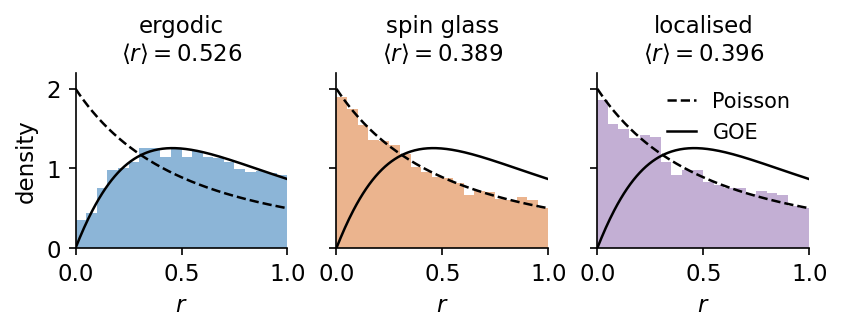

In [7]:
def even_sector(n):
    # basis states with an even number of spins down, eigenvalue +1 of the parity Z_1 Z_2 ... Z_n
    _, z = basis_spins(n)
    return np.nonzero(np.prod(z, axis=1) == 1)[0]

def r_values(n, h, W, keys):
    ev = even_sector(n)
    one = lambda k: gap_ratio(jnp.linalg.eigvalsh(hamiltonian(n, h, W, k)[ev][:, ev]))
    return jax.vmap(one)(keys)
r_values = jax.jit(r_values, static_argnums=0)

# histograms of r_n for N = 10 qubits (256 levels of the central half per draw) at the three parameter points
N_HIST, N_REAL_HIST = 10, 40
keys_hist = jax.random.split(jax.random.key(70), N_REAL_HIST)
r_hist = {name: np.asarray(r_values(N_HIST, p["h"], p["W"], keys_hist)).ravel() for name, p in REG.items()}
# distributions of r in [0, 1]: Poisson 2/(1+r)^2, and the GOE surmise of Atas et al.
r_ax = np.linspace(0, 1, 201)
P_poi = 2 / (1 + r_ax) ** 2
P_goe = 2 * (27 / 8) * (r_ax + r_ax ** 2) / (1 + r_ax + r_ax ** 2) ** 2.5
print(f"normalisation on [0, 1]: Poisson {np.trapezoid(P_poi, r_ax):.4f}, GOE surmise {np.trapezoid(P_goe, r_ax):.4f}")
nums["r_hist"] = {name: dict(mean=float(v.mean()), n=int(v.size), small=float((v < 0.1).mean())) for name, v in r_hist.items()}
nums["r_hist_ref_small"] = dict(poisson=float(1 - 2 / 1.1 + 1), goe=float(np.trapezoid(P_goe[r_ax <= 0.1], r_ax[r_ax <= 0.1])))
for name, v in nums["r_hist"].items():
    print(f"{name:10s} N = {N_HIST}: <r> = {v['mean']:.3f} from {v['n']} ratios, fraction with r < 0.1: {v['small']:.3f}")
print(f"fraction with r < 0.1: Poisson {nums['r_hist_ref_small']['poisson']:.3f}, GOE surmise {nums['r_hist_ref_small']['goe']:.3f}")

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.1), layout="constrained", sharey=True)
    for ax, (name, p) in zip(axs, REG.items()):
        ax.hist(r_hist[name], bins=20, range=(0, 1), density=True, color=p["color"], alpha=0.45, lw=0)
        ax.plot(r_ax, P_poi, color="k", ls="--", lw=1.2, label="Poisson")
        ax.plot(r_ax, P_goe, color="k", lw=1.2, label="GOE")
        ax.set_title(f"{name}\n" + rf"$\langle r\rangle={r_hist[name].mean():.3f}$", fontsize=11)
        ax.set_xlabel("$r$"); ax.set_xlim(0, 1); ax.set_xticks([0, 0.5, 1])
    axs[0].set_ylabel("density"); axs[0].set_ylim(0, 2.2)
    axs[2].legend(loc="upper right", fontsize=10, handlelength=1.4)
    save(fig, "fig_lab047_r_hist"); plt.show()

At the ergodic point the histogram follows the GOE curve, with $\langle r\rangle=0.526$ and only $3.9\%$ of the ratios below $0.1$, against $3.0\%$ for the GOE surmise and $18.2\%$ for Poisson statistics. At the spin-glass and localised points the histograms follow the Poisson curve, with $18.3\%$ and $17.1\%$ of the ratios below $0.1$. Ten qubits are used here because the six-qubit ergodic point lies in the crossover discussed below.

We now diagonalise $\hat H$ in the even sector on a logarithmic grid of $h/J_s$ and $D/J_s$ from $10^{-2}$ to $10^{2}$ for $N=8$ qubits, which gives $128$ levels per draw, and average over $24$ draws per point. Cuts at $D=0$ for $N=6$, $8$ and $10$ show how the picture changes with the size of the register. The circles in the map mark the three parameter points used for the reservoir below, labelled by the regimes of Martínez-Peña *et al.*, ergodic at $(h,D)=(10,0)J_s$, spin glass at $(0.01,0)J_s$ and localised at $(1,100)J_s$.

In [8]:
t0 = time.time()
GRID = np.logspace(-2, 2, 13)                     # h / J_s and D / J_s
N_MAP, N_REAL_MAP = 8, 24
keys_map = jax.random.split(jax.random.key(11), N_REAL_MAP)
r_map = np.array([[float(r_values(N_MAP, h, W, keys_map).mean()) for h in GRID] for W in GRID])
print(f"map of <r> for N = {N_MAP}, {len(GRID)} x {len(GRID)} points, {N_REAL_MAP} draws each: {time.time() - t0:.0f} s")

# cuts at D = 0 for three register sizes, and the three regimes at the reservoir size N = 6
CUT_H = np.logspace(-2, 2, 11)
N_REAL_CUT = {6: 200, 8: 40, 10: 8}
r_cut = {}
for n, nr in N_REAL_CUT.items():
    ks = jax.random.split(jax.random.key(20 + n), nr)
    rows = []
    for h in CUT_H:
        r = np.asarray(r_values(n, h, 0.0, ks))            # (draws, levels)
        rows.append((r.mean(), r.mean(axis=1).std() / np.sqrt(nr)))
    r_cut[n] = np.array(rows)
print(f"cuts at D = 0 for N = 6, 8, 10: {time.time() - t0:.0f} s in total")
r_regime = {}
for name, p in REG.items():
    for n in (6, N_MAP):
        ks = jax.random.split(jax.random.key(30 + n), N_REAL_CUT[n])
        r_regime[f"{name} N{n}"] = float(r_values(n, p["h"], p["W"], ks).mean())
    print(f"{name:10s} (h = {p['h']}, D = {p['W']}): <r> = {r_regime[name + ' N6']:.3f} for N = 6, {r_regime[name + ' N8']:.3f} for N = 8")
nums["r_regime"] = r_regime
nums["r_map_range"] = [float(r_map.min()), float(r_map.max())]
nums["r_cut"] = {n: dict(h=CUT_H.tolist(), r=r_cut[n][:, 0].tolist()) for n in r_cut}

map of <r> for N = 8, 13 x 13 points, 24 draws each: 69 s


cuts at D = 0 for N = 6, 8, 10: 107 s in total


ergodic    (h = 10.0, D = 0.0): <r> = 0.457 for N = 6, 0.472 for N = 8


spin glass (h = 0.01, D = 0.0): <r> = 0.399 for N = 6, 0.398 for N = 8


localised  (h = 1.0, D = 100.0): <r> = 0.369 for N = 6, 0.372 for N = 8


The left panel shows $\langle r\rangle$ over the plane of field $h/J_s$ and disorder $D/J_s$ for $N=8$, with values between $0.36$ and $0.54$. The right panel shows $\langle r\rangle$ against $h/J_s$ at $D=0$ for $N=6$, $8$ and $10$, with error bars of one standard error over the draws, and the dotted lines mark the computed GOE and Poisson values. The Roman numerals follow Martínez-Peña *et al.*, who found the same four regions for $N=10$.

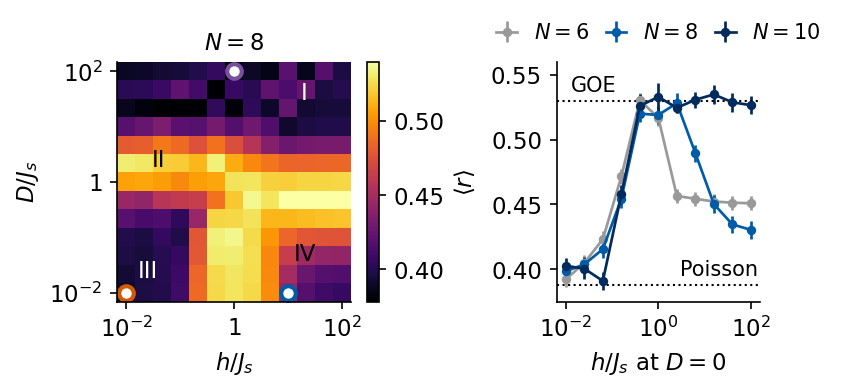

In [9]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.5), layout="constrained", gridspec_kw={"width_ratios": [1.15, 1.0]})
    ax = axs[0]
    lg = np.log10(GRID)
    pc = ax.pcolormesh(lg, lg, r_map, cmap="inferno", vmin=R_POI - 0.01, vmax=R_GOE + 0.01, shading="nearest")
    cb = fig.colorbar(pc, ax=ax, pad=0.02); cb.set_label(r"$\langle r\rangle$")
    for name, p in REG.items():
        ax.plot(np.log10(p["h"]), np.log10(max(p["W"], 1e-2)), marker="o", ms=7, mfc="white", mec=p["color"], mew=2)
    ax.text(np.log10(0.025), np.log10(0.025), "III", color="white", fontsize=11, ha="center", va="center")
    ax.text(np.log10(20), np.log10(0.05), "IV", color="k", fontsize=11, ha="center", va="center")
    ax.text(np.log10(0.04), np.log10(2.5), "II", color="k", fontsize=11, ha="center", va="center")
    ax.text(np.log10(20), np.log10(40), "I", color="white", fontsize=11, ha="center", va="center")
    ax.set_xticks([-2, 0, 2], ["$10^{-2}$", "$1$", "$10^{2}$"]); ax.set_yticks([-2, 0, 2], ["$10^{-2}$", "$1$", "$10^{2}$"])
    ax.set_xlabel(r"$h/J_s$"); ax.set_ylabel(r"$D/J_s$"); ax.set_title(f"$N={N_MAP}$", fontsize=11)
    ax = axs[1]
    for n, col in zip((6, 8, 10), ("0.6", UJBlue, UJNavy)):
        ax.errorbar(CUT_H, r_cut[n][:, 0], yerr=r_cut[n][:, 1], color=col, marker="o", ms=3.5, lw=1.3, capsize=0, label=f"$N={n}$")
    ax.axhline(R_GOE, color="k", ls=":", lw=1.0); ax.axhline(R_POI, color="k", ls=":", lw=1.0)
    ax.text(1.3e-2, R_GOE + 0.004, "GOE", va="bottom", fontsize=10); ax.text(3e0, R_POI + 0.004, "Poisson", va="bottom", fontsize=10)
    ax.set_xscale("log"); ax.set_xlabel(r"$h/J_s$ at $D=0$")
    ax.set_xticks([1e-2, 1, 1e2]); ax.set_ylim(0.375, 0.56)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, fontsize=10, handlelength=1.0, columnspacing=0.8)
    save(fig, "fig_lab047_gap_ratio"); plt.show()

Four regions appear. For $D\gg J_s$ (region I) the random fields dominate, the eigenstates are close to product states in the $\hat Z$ basis, and $\langle r\rangle$ is close to the Poisson value. This is the regime called many-body localised (MBL), where an excitation stays near the site where it was created [D. A. Abanin, E. Altman, I. Bloch, M. Serbyn, Rev. Mod. Phys. **91**, 021001 (2019), [doi:10.1103/RevModPhys.91.021001](https://doi.org/10.1103/RevModPhys.91.021001)]. For $h,D\ll J_s$ (region III) the couplings dominate. The Hamiltonian is then close to $\sum_{i<j}J_{ij}\hat X_i\hat X_j$, a classical Ising model in the $\hat X$ basis with couplings of random sign, which is a spin glass. Its eigenstates are close to product states in the $\hat X$ basis, and the statistics is again close to Poisson. Between these limits, where the couplings compete with a field or with disorder of comparable size (regions II and IV), the levels repel and $\langle r\rangle$ approaches the GOE value. These are the ergodic regimes, in which an initial excitation spreads over the whole register.

The cuts show a finite-size effect at large field. For $N=10$, $\langle r\rangle$ stays at the GOE value up to $h=100J_s$, while for $N=6$ it drops to about $0.45$ above $h\approx2.5J_s$ and for $N=8$ to about $0.43$ at $h=100J_s$. For $h\gg J_s$ the spectrum splits into bands of fixed magnetisation $\sum_i\hat Z_i$, separated by $h$. For $N=6$ the even sector has bands of $15$ levels with two and with four spins down, at energies near $+h$ and $-h$, and the central half of the spectrum contains the gap between them. The two ratios $r_n$ that involve this gap are close to zero, and with only about $14$ ratios per draw they lower the average to about $0.45$. For $N=8$ the central band has zero magnetisation. The global spin flip $\hat F=\hat X_1\hat X_2\cdots \hat X_N$ maps this band onto itself and commutes with the couplings, and only the field term breaks the symmetry. The next cell shows that the central eigenstates become nearly eigenstates of $\hat F$ as $h$ grows, so the band splits into two almost independent spectra, which lowers $\langle r\rangle$. For $N=10$ the even sector has no band of zero magnetisation, and the eigenstates show no such symmetry.

At the ergodic point $(h,D)=(10,0)J_s$ the six-qubit register therefore has $\langle r\rangle=0.457$, between the two reference values, and the eight-qubit register $0.472$. The spin-glass and localised points have $0.399$ and $0.369$ at $N=6$, close to the Poisson value. We keep the three points of the published study for comparison and remember that at $N=6$ the ergodic point lies in a crossover.

In [10]:
def flip_expectation(n, h, key):
    # |<F>| for the central half of the even-sector eigenstates, F = X_1 X_2 ... X_N the global spin flip
    idx, _ = basis_spins(n)
    ev = even_sector(n)
    E, V = np.linalg.eigh(np.asarray(hamiltonian(n, h, 0.0, key))[np.ix_(ev, ev)])
    full = np.zeros((2 ** n, len(ev))); full[ev] = V
    f = np.abs(np.einsum("ij,ij->j", full[(2 ** n - 1) - idx], full))   # F maps basis state idx to 2^n - 1 - idx
    m = len(ev)
    return f[m // 4: 3 * m // 4].mean()

nums["flip"] = {}
for n in (8, 10):
    vals = [np.mean([flip_expectation(n, h, jax.random.key(s)) for s in range(4)]) for h in (2.5, 16.0, 100.0)]
    nums["flip"][n] = vals
    print(f"N = {n}: mean |<X_1...X_N>| over the central eigenstates at h = 2.5, 16, 100: " + ", ".join(f"{v:.3f}" for v in vals))

N = 8: mean |<X_1...X_N>| over the central eigenstates at h = 2.5, 16, 100: 0.422, 0.896, 0.981


N = 10: mean |<X_1...X_N>| over the central eigenstates at h = 2.5, 16, 100: 0.038, 0.008, 0.001


For $N=8$ the mean of $|\langle \hat F\rangle|$ over the central eigenstates grows from $0.42$ at $h=2.5J_s$ to $0.98$ at $h=100J_s$, while for $N=10$ it stays below $0.04$. The drop of $\langle r\rangle$ at large field in the smaller registers thus comes from the band structure of the spectrum and disappears at $N=10$ in our data.

The conserved quantities, the imprint and the level statistics give one picture. Where $\langle r\rangle$ is close to the Poisson value the register has nearly conserved local quantities and keeps a local imprint. Where $\langle r\rangle$ is close to the GOE value it scrambles the imprint and forgets it. The following sections show that the reservoir forgets its initial state in the chaotic regime and that its memory of past inputs is largest in the chaotic regime near its border with the spin glass and with localisation.

<hr/>
## 3. One reservoir step

The input sequence $s_1,s_2,\dots$ with $s_k\in[0,1]$ enters the register one value per step. At step $k$ qubit 1 is reset to the pure state
$$
|\psi(s_k)\rangle=\sqrt{1-s_k}\,|0\rangle+\sqrt{s_k}\,|1\rangle ,
$$
its previous state is discarded by the partial trace $\mathrm{Tr}_1$ over qubit 1, and the whole register evolves for the time $\Delta t$ with $\hat U=e^{-i\hat H\Delta t}$,
$$
\hat\rho_k=\mathcal T_{s_k}(\hat\rho_{k-1})=\hat U\Big(|\psi(s_k)\rangle\langle\psi(s_k)|\otimes\mathrm{Tr}_1\,\hat\rho_{k-1}\Big)\hat U^\dagger .
$$
We use $J_s\Delta t=10$ as in the published study. The map $\mathcal T_s$ is linear in $\hat\rho$, it preserves the trace and the positivity of $\hat\rho$, and it is a quantum channel. The reset of qubit 1 is the only place where the register loses information, and it lets the reservoir forget its initial state.

Writing $\hat U=(\hat U_0\;\hat U_1)$ in blocks of columns that act on the states with qubit 1 in $|0\rangle$ and in $|1\rangle$, the step takes the compact form
$$
\mathcal T_s(\hat\rho)=\hat A_s\,\big(\mathrm{Tr}_1\hat\rho\big)\,\hat A_s^\dagger,\qquad \hat A_s=\hat U\big(|\psi(s)\rangle\otimes\hat I\big)=\sqrt{1-s}\,\hat U_0+\sqrt s\,\hat U_1 ,
$$
with a $2^N\times2^{N-1}$ matrix $\hat A_s$. This form avoids the Kronecker product and reduces the cost of the matrix products by a factor of about $2.7$, from $2\cdot8^N$ to $\tfrac34\cdot8^N$ multiplications.

The features are expectation values of Pauli strings, products of Pauli matrices on a few qubits,
$$
x_{k,\alpha}=\mathrm{Tr}\big(\hat P_\alpha\,\hat\rho_k\big),\qquad \hat P_\alpha\in\{\hat X_i,\,\hat Y_i,\,\hat Z_i,\,\hat X_i\hat X_j,\,\hat Y_i\hat Y_j,\,\hat Z_i\hat Z_j\},
$$
which gives $M=3N+3N(N-1)/2=63$ features for $N=6$, compared with $4^N-1=4095$ real numbers that fix $\hat\rho_k$. Each feature is linear in $\hat\rho_k$, and the output $\tilde y_k=\mathbf w^\top\mathbf x_k+b$ is fitted by ridge regression.

The picture is that of a linear lifting. The density matrix lives in a space of dimension $4^N$ and evolves linearly, and the features are linear functions on this space, which recalls the Koopman description of a nonlinear system by linear dynamics of observables. The nonlinearity in the input comes from the encoding. After one step every feature is a combination of $1-s$, $s$ and $\sqrt{s(1-s)}$, because $\hat A_s$ contains $\sqrt{1-s}$ and $\sqrt s$ and enters the step twice. Repeated steps multiply such functions of $s_k,s_{k-1},\dots$, so $\hat\rho_k$ becomes a polynomial-like function of the input history whose dependence on older inputs is weakened by the resets. The next cell implements the step and the scan over an input sequence. A dephasing factor $\gamma$ is included for the weak measurement discussed at the end of the notebook and equals one for $g=0$.

In [11]:
def unitary(H, dt=DT):
    # U = exp(-i H dt) from the eigendecomposition of the real symmetric H
    E, V = jnp.linalg.eigh(H)
    return (V * jnp.exp(-1j * E * dt)) @ V.conj().T

def partial_trace_1(rho):
    # Tr_1 rho: the reduced density matrix of qubits 2..N
    r = rho.reshape(2, DIM // 2, 2, DIM // 2)
    return r[0, :, 0, :] + r[1, :, 1, :]

def reservoir_map(U, rho, s):
    # T_s(rho) = U (|psi(s)><psi(s)| x Tr_1 rho) U^dag = A_s (Tr_1 rho) A_s^dag with A_s = U (|psi(s)> x 1)
    A = jnp.sqrt(1 - s) * U[:, :DIM // 2] + jnp.sqrt(s) * U[:, DIM // 2:]
    return A @ partial_trace_1(rho) @ A.conj().T

STRINGS = ([((i,), a) for i in range(N) for a in "XYZ"]
           + [((i, j), a) for i in range(N) for j in range(i + 1, N) for a in "XYZ"])
M_FEAT = len(STRINGS)
IS_Z = np.array([a == "Z" for _, a in STRINGS])                  # the strings Z_i and Z_i Z_j
P_MATS = np.array([pauli_string(N, {q: a for q in qs}) for qs, a in STRINGS])
P_VEC = jnp.asarray(P_MATS.transpose(0, 2, 1).reshape(M_FEAT, -1))   # Tr(P rho) = vec(P^T) . vec(rho)
HAMMING = jnp.asarray((basis_spins(N)[1][:, None, :] != basis_spins(N)[1][None, :, :]).sum(-1), jnp.float64)

def run_reservoir(U, s, g=0.0, rho0=None):
    # features x_k for the input sequence s; g > 0 adds the averaged back-action of a weak measurement
    gamma = jnp.exp(-0.5 * g ** 2 * HAMMING)
    def step(rho, sk):
        rho = reservoir_map(U, rho, sk)
        return gamma * rho, jnp.real(P_VEC @ rho.ravel())
    rho0 = jnp.eye(DIM, dtype=jnp.complex128) / DIM if rho0 is None else rho0
    return jax.lax.scan(step, rho0, s)[1]

@jax.jit
def qrc_features(h, W, key, s, g, dt):
    return run_reservoir(unitary(hamiltonian(N, h, W, key), dt), s, g)
qrc_features_batch = jax.jit(jax.vmap(qrc_features, in_axes=(None, None, 0, None, None, None)))
print(f"N = {N} qubits, density matrix {DIM} x {DIM}, {M_FEAT} features "
      f"({3 * N} one-qubit and {3 * N * (N - 1) // 2} two-qubit Pauli strings), 4^N - 1 = {4 ** N - 1}")
nums["N"], nums["M_feat"], nums["M_Z"] = N, M_FEAT, int(IS_Z.sum())

N = 6 qubits, density matrix 64 x 64, 63 features (18 one-qubit and 45 two-qubit Pauli strings), 4^N - 1 = 4095


We check the implementation on a random density matrix $\hat\rho=GG^\dagger/\mathrm{Tr}(GG^\dagger)$ built from a complex Gaussian matrix $G$. The compact form must agree with the Kronecker-product form, the result must have unit trace, be Hermitian and have no negative eigenvalues, and the map must be linear in $\hat\rho$. We also fit all $63$ features after one step, as functions of $s$, with the three functions $1-s$, $s$ and $\sqrt{s(1-s)}$, and for comparison with the two linear functions alone.

In [12]:
def random_density_matrix(key, d=DIM):
    # rho = G G^dag / Tr(G G^dag) with a complex Gaussian matrix G
    k1, k2 = jax.random.split(key)
    G = jax.random.normal(k1, (d, d)) + 1j * jax.random.normal(k2, (d, d))
    rho = G @ G.conj().T
    return rho / jnp.trace(rho).real

ks = jax.random.split(jax.random.key(5), 4)
U_chk = unitary(hamiltonian(N, REG["ergodic"]["h"], 0.0, ks[0]))
rho_a, rho_b = random_density_matrix(ks[1]), random_density_matrix(ks[2])
s0 = 0.37
psi = np.array([np.sqrt(1 - s0), np.sqrt(s0)])
T_a = reservoir_map(U_chk, rho_a, s0)
T_kron = U_chk @ jnp.kron(jnp.outer(psi, psi), partial_trace_1(rho_a)) @ U_chk.conj().T
print("max |A_s Tr_1(rho) A_s^dag - U (psi psi^dag x Tr_1 rho) U^dag| =", float(jnp.abs(T_a - T_kron).max()))
print(f"Tr T(rho) = {float(jnp.trace(T_a).real):.15f}, max |T - T^dag| = {float(jnp.abs(T_a - T_a.conj().T).max()):.1e},"
      f" smallest eigenvalue {float(jnp.linalg.eigvalsh(T_a).min()):.1e}")
a, b = 0.3, 0.7
lin = jnp.abs(reservoir_map(U_chk, a * rho_a + b * rho_b, s0) - a * T_a - b * reservoir_map(U_chk, rho_b, s0)).max()
print("linearity in rho: max |T(a rho + b sigma) - a T(rho) - b T(sigma)| =", float(lin))

# dependence on the input after one step: every feature is a combination of 1 - s, s and sqrt(s (1 - s))
s_grid = np.linspace(0, 1, 41)
X_one = np.array([np.asarray(jnp.real(P_VEC @ reservoir_map(U_chk, rho_a, s).ravel())) for s in s_grid])
B3 = np.c_[1 - s_grid, s_grid, np.sqrt(s_grid * (1 - s_grid))]
coef3 = np.linalg.lstsq(B3, X_one, rcond=None)[0]
coef2 = np.linalg.lstsq(B3[:, :2], X_one, rcond=None)[0]
res3, res2 = np.abs(B3 @ coef3 - X_one).max(), np.abs(B3[:, :2] @ coef2 - X_one).max()
nums["one_step_fit"] = dict(res_three=float(res3), res_linear=float(res2))
print(f"one step, all {M_FEAT} features: max residual of the fit with (1-s, s, sqrt(s(1-s))) = {res3:.1e},"
      f" with (1-s, s) only = {res2:.2f}")

max |A_s Tr_1(rho) A_s^dag - U (psi psi^dag x Tr_1 rho) U^dag| = 1.0728672184036493e-17


Tr T(rho) = 1.000000000000001, max |T - T^dag| = 1.0e-17, smallest eigenvalue -1.6e-17


linearity in rho: max |T(a rho + b sigma) - a T(rho) - b T(sigma)| = 1.2186898127241852e-17


one step, all 63 features: max residual of the fit with (1-s, s, sqrt(s(1-s))) = 2.2e-16, with (1-s, s) only = 0.07


All checks hold to rounding errors of order $10^{-16}$. The three functions fit every feature after one step with a maximal residual of $2.2\times10^{-16}$, while the linear functions alone leave a residual of $0.07$. A single step therefore produces a nonlinear function of the input, of the form fixed by the encoding, from a dynamics that is linear in $\hat\rho$.

<hr/>
## 4. Fading memory and the echo state property

A reservoir is useful only when its state after a long input sequence depends on the inputs and on nothing else. This is the echo state property, introduced for classical ESNs [H. Jaeger, H. Haas, Science **304**, 78 (2004), [doi:10.1126/science.1091277](https://doi.org/10.1126/science.1091277)]. For the quantum reservoir we test it with two copies of the register, prepared in different random density matrices $\hat\rho_A(0)$ and $\hat\rho_B(0)$ and driven by the same inputs $s_k$ drawn uniformly from $[0,1]$. We follow their trace distance
$$
D_k=\tfrac12\big\|\hat\rho_A(k)-\hat\rho_B(k)\big\|_1=\tfrac12\sum_n|\lambda_n|,
$$
where $\lambda_n$ are the eigenvalues of the Hermitian matrix $\hat\rho_A(k)-\hat\rho_B(k)$. The trace distance is the largest difference of the probability of any measurement outcome between the two states, and a quantum channel can only decrease it, so $D_k$ never grows. Because $\mathcal T_s$ is linear, the difference $\hat\Delta_k=\hat\rho_A(k)-\hat\rho_B(k)$ obeys the same map, and we propagate $\hat\Delta_k$ directly. We use $10$ draws of the couplings per regime and $300$ input steps.

At $h=0$ and $D=0$ the test has an exact answer. The operators $\hat X_2,\dots,\hat X_N$ then commute with $\hat H$, and the reset of qubit 1 leaves their expectation values unchanged, so the differences $\mathrm{Tr}(\hat X_j\hat\Delta_k)$ for $j\ge2$ are conserved and $D_k$ stays bounded away from zero. We check this conservation numerically as well.

In [13]:
@jax.jit
def esp_distance(h, W, key, s):
    # trace distance D_k = ||rho_A(k) - rho_B(k)||_1 / 2 of two copies driven by the same inputs
    kH, kA, kB = jax.random.split(key, 3)
    U = unitary(hamiltonian(N, h, W, kH))
    delta = random_density_matrix(kA) - random_density_matrix(kB)   # T is linear, so the difference obeys the same map
    tdist = lambda d: 0.5 * jnp.sum(jnp.abs(jnp.linalg.eigvalsh(d)))
    def step(d, sk):
        d = reservoir_map(U, d, sk)
        return d, tdist(d)
    return jnp.concatenate([tdist(delta)[None], jax.lax.scan(step, delta, s)[1]])

K_ESP, N_REAL_ESP = 300, 10
s_esp = jnp.asarray(np.random.default_rng(1).uniform(0, 1, K_ESP))
keys_esp = jax.random.split(jax.random.key(40), N_REAL_ESP)
esp_batch = jax.jit(jax.vmap(esp_distance, in_axes=(None, None, 0, None)))
D_esp = {name: np.asarray(esp_batch(p["h"], p["W"], keys_esp, s_esp)) for name, p in REG.items()}
k_ax = np.arange(K_ESP + 1)
med = np.median(D_esp["ergodic"], axis=0)
fit_range = (med > 1e-11) & (k_ax >= 5)
slope = np.polyfit(k_ax[fit_range], np.log(med[fit_range]), 1)[0]
nums["esp"] = {name: dict(D0=float(np.median(D[:, 0])), D_end=float(np.median(D[:, -1]))) for name, D in D_esp.items()}
nums["esp"]["ergodic"]["rate"] = float(-slope)
nums["esp"]["ergodic"]["k_1e-10"] = int(np.argmax(med < 1e-10))
for name, D in D_esp.items():
    print(f"{name:10s} median D_0 = {np.median(D[:, 0]):.3f}, median D_{K_ESP} = {np.median(D[:, -1]):.2e}")
print(f"ergodic: D_k ~ exp(-{-slope:.3f} k), median below 1e-10 after k = {nums['esp']['ergodic']['k_1e-10']} steps")

# at h = 0 the operators X_2, ..., X_N commute with H and are untouched by the reset of qubit 1
U0 = unitary(hamiltonian(N, 0.0, 0.0, keys_esp[0]))
Xop = jnp.asarray(np.array([pauli_string(N, {i: "X"}) for i in range(1, N)]))
dA = random_density_matrix(keys_esp[1]) - random_density_matrix(keys_esp[2])
x_before = jnp.real(jnp.einsum("aij,ji->a", Xop, dA))
dB = jax.lax.scan(lambda d, sk: (reservoir_map(U0, d, sk), None), dA, s_esp)[0]
x_after = jnp.real(jnp.einsum("aij,ji->a", Xop, dB))
nums["esp"]["h0_conserved_err"] = float(jnp.abs(x_after - x_before).max())
print(f"h = 0: differences of <X_j>, j = 2..{N}, before {np.round(np.asarray(x_before), 4)}, change after {K_ESP} steps "
      f"{nums['esp']['h0_conserved_err']:.1e}")

ergodic    median D_0 = 0.568, median D_300 = 1.30e-16
spin glass median D_0 = 0.568, median D_300 = 6.24e-02
localised  median D_0 = 0.568, median D_300 = 2.07e-01
ergodic: D_k ~ exp(-0.118 k), median below 1e-10 after k = 161 steps


h = 0: differences of <X_j>, j = 2..6, before [ 0.0081 -0.0178  0.0031  0.0109  0.0002], change after 300 steps 1.1e-14


The figure shows the median of $D_k$ over the draws against the input step $k$, with bands from the 16th to the 84th percentile, for the three regimes.

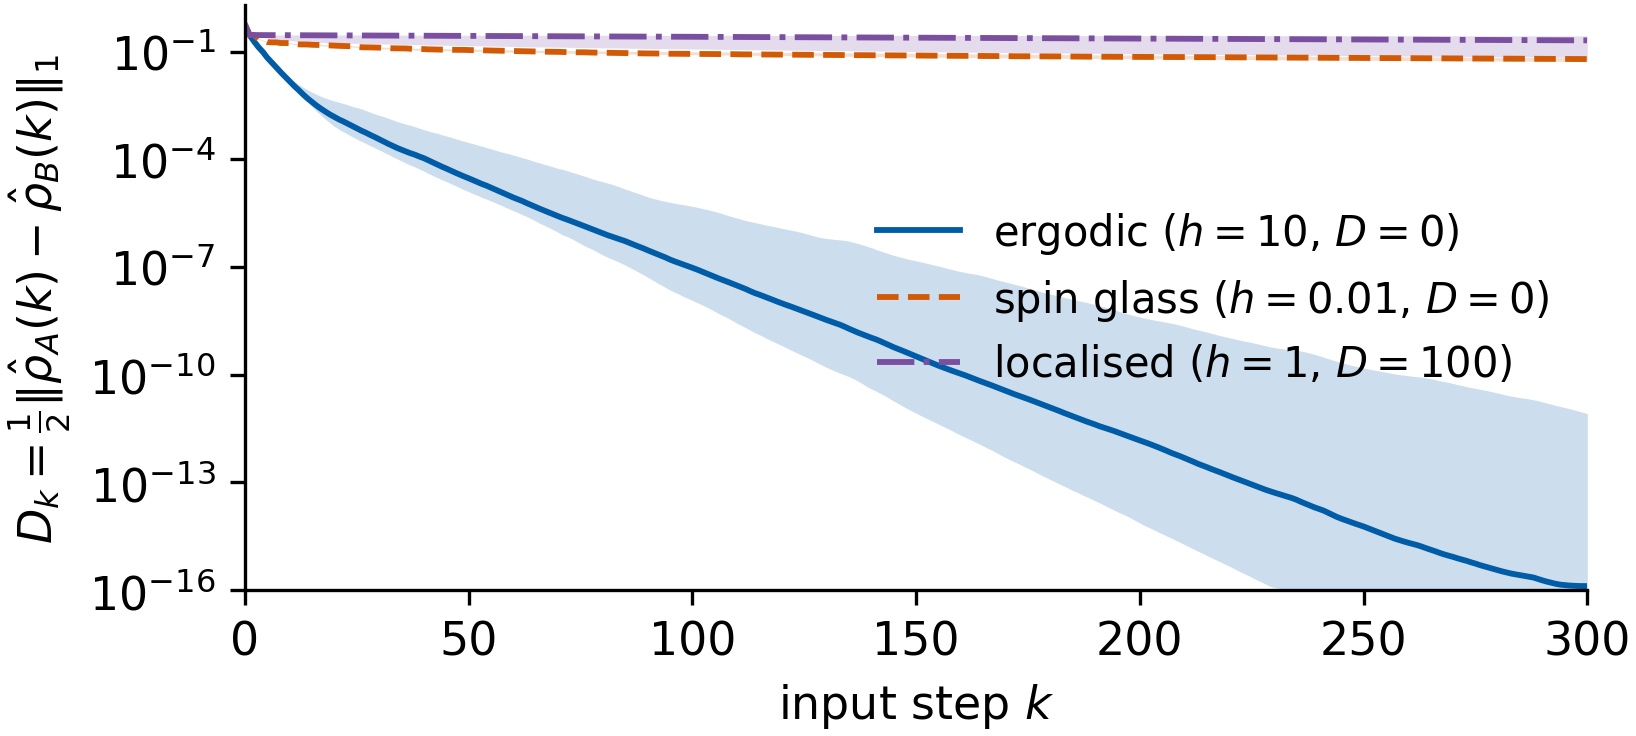

In [14]:
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.5), layout="constrained")
    for name, p in REG.items():
        D = np.maximum(D_esp[name], 1e-16)
        lo, hi = np.percentile(D, [16, 84], axis=0)
        ax.fill_between(k_ax, lo, hi, color=p["color"], alpha=0.2, lw=0)
        ax.semilogy(k_ax, np.median(D, axis=0), color=p["color"], ls=p["ls"],
                    label=f"{name} ($h={p['h']:g}$, $D={p['W']:g}$)")
    ax.set_xlim(0, K_ESP); ax.set_ylim(1e-16, 2)
    ax.set_xlabel("input step $k$"); ax.set_ylabel(r"$D_k=\frac{1}{2}\|\hat\rho_A(k)-\hat\rho_B(k)\|_1$")
    ax.legend(loc="center right", fontsize=10)
    save(fig, "fig_lab047_esp_distance"); plt.show()

In the ergodic regime the distance decays exponentially, $D_k\propto e^{-0.118\,k}$, and the median falls below $10^{-10}$ after $161$ steps and reaches $1.3\times10^{-16}$, the level of rounding errors, at $k=300$. The two copies become identical, and the echo state property holds. In the spin-glass regime the median is still $6.2\times10^{-2}$ after $300$ steps, and in the localised regime $0.21$, compared with the initial $0.568$. In both cases the register keeps a trace of its initial state for hundreds of steps. At $h=0$ the differences of $\langle \hat X_j\rangle$ for $j=2,\dots,6$ stay at their initial values to $1.1\times10^{-14}$ after $300$ steps, which confirms the exact conservation. The small field $h=0.01J_s$ breaks it only weakly, and the slow decay in the spin-glass regime follows from these nearly conserved quantities. In the localised regime the random fields keep the information near the qubits where it is, and qubit 1, whose state is replaced at every step, exchanges little with the rest of the register.

The same mechanism controls the memory of the inputs. An input that enters qubit 1 is erased at the next reset unless the dynamics has moved it to other qubits within the time $\Delta t$, and an input stored in the register fades only as fast as the register forgets. Fading memory and the echo state property are therefore two sides of the contraction of the reservoir map.

<hr/>
## 5. Memory capacity across the regimes

The memory of a reservoir is measured by recall tasks. For an input sequence $s_k$ drawn independently and uniformly from $[0,1]$, a linear readout is trained to output the input $d$ steps back, $y_k=s_{k-d}$, and its quality on test data is scored by the capacity
$$
C(d)=r^2\big(\tilde y,y\big)=\frac{\operatorname{cov}^2(\tilde y,y)}{\operatorname{var}(\tilde y)\operatorname{var}(y)}\in[0,1].
$$
The memory capacity is the sum $\mathrm{MC}=\sum_{d=1}^{40}C(d)$. For a reservoir with $M$ linearly independent features the linear memory capacity summed over all delays is at most $M$ [J. Dambre, D. Verstraeten, B. Schrauwen, S. Massar, Sci. Rep. **2**, 514 (2012), [doi:10.1038/srep00514](https://doi.org/10.1038/srep00514)].

The recall tasks measure linear memory only. A task that needs memory and nonlinearity together is the nonlinear autoregressive moving average (NARMA) of order $n$, driven by $u_k=s_k/2\in[0,0.5]$. NARMA-2 follows
$$
y_{k+1}=0.4\,y_k+0.4\,y_ky_{k-1}+0.6\,u_k^3+0.1
$$
[A. F. Atiya, A. G. Parlos, IEEE Trans. Neural Netw. **11**, 697 (2000), [doi:10.1109/72.846741](https://doi.org/10.1109/72.846741)], and NARMA-10 follows
$$
y_{k+1}=0.3\,y_k+0.05\,y_k\sum_{j=0}^{9}y_{k-j}+1.5\,u_{k-9}u_k+0.1 .
$$
We score both with $C=r^2(\tilde y,y)$, as Martínez-Peña *et al.* do.

Each run has $3000$ steps from the maximally mixed state $\hat I/2^N$. The first $200$ steps are discarded as washout, the next $1400$ are used for training, $400$ for validation and the last $1000$ for testing. The ridge strength $\beta$ of the readout is chosen for every target from four values by the validation score, and the reported capacities are test scores. Our ridge regression agrees with scikit-learn.

In [15]:
K_WASH, K_TR, K_VA, K_TE = 200, 1400, 400, 1000      # washout, training, validation and test steps
K_TOT = K_WASH + K_TR + K_VA + K_TE
TR = slice(K_WASH, K_WASH + K_TR); VA = slice(K_WASH + K_TR, K_WASH + K_TR + K_VA); TE = slice(K_TOT - K_TE, K_TOT)
D_MAX = 40
BETAS = (1e-8, 1e-6, 1e-4, 1e-2)

def ridge_fit(F, Y, beta):
    # centred ridge regression, F: (n, M) features, Y: (n, T) targets -> W (M, T), b (T,)
    fm, ym = F.mean(0), Y.mean(0)
    Fc, Yc = F - fm, Y - ym
    W = np.linalg.solve(Fc.T @ Fc + beta * np.eye(F.shape[1]), Fc.T @ Yc)
    return W, ym - fm @ W

def r2(pred, true):
    # squared Pearson correlation for every column
    p, t = pred - pred.mean(0), true - true.mean(0)
    return np.sum(p * t, 0) ** 2 / (np.sum(p * p, 0) * np.sum(t * t, 0))

def capacities(F, Y, betas=BETAS):
    # C = r^2 on the test block for every target column, ridge strength chosen per column on the validation block
    best_v, best_t = np.full(Y.shape[1], -1.0), np.zeros(Y.shape[1])
    for beta in betas:
        W, b = ridge_fit(F[TR], Y[TR], beta)
        cv, ct = r2(F[VA] @ W + b, Y[VA]), r2(F[TE] @ W + b, Y[TE])
        better = cv > best_v
        best_v[better], best_t[better] = cv[better], ct[better]
    return best_t, best_v

def narma(u, n):
    # NARMA-2 (Atiya and Parlos) and NARMA-n, n >= 3, driven by u in [0, 0.5]
    y = np.zeros_like(u)
    for k in range(n, len(u) - 1):
        if n == 2:
            y[k + 1] = 0.4 * y[k] + 0.4 * y[k] * y[k - 1] + 0.6 * u[k] ** 3 + 0.1
        else:
            y[k + 1] = 0.3 * y[k] + 0.05 * y[k] * y[k - n + 1:k + 1].sum() + 1.5 * u[k - n + 1] * u[k] + 0.1
    return y

s_mem = np.random.default_rng(0).uniform(0, 1, K_TOT)
Y_delay = np.stack([np.roll(s_mem, d) for d in range(1, D_MAX + 1)], axis=1)   # y_k = s_{k-d}, valid after the washout
Y_narma = np.stack([narma(0.5 * s_mem, 2), narma(0.5 * s_mem, 10)], axis=1)
Y_all = np.concatenate([Y_delay, Y_narma], axis=1)

# ridge regression checked against scikit-learn
rng = np.random.default_rng(2)
F_t, Y_t = rng.normal(size=(300, 20)), rng.normal(size=(300, 3))
W_t, b_t = ridge_fit(F_t, Y_t, 0.5)
sk = SkRidge(alpha=0.5).fit(F_t, Y_t)
print("max |W - W_sklearn| =", np.abs(W_t - sk.coef_.T).max(), "| max |b - b_sklearn| =", np.abs(b_t - sk.intercept_).max())

N_REAL = 3
keys_mem = jax.random.split(jax.random.key(50), 4)
s_mem_j = jnp.asarray(s_mem)
def qrc_scores(h, W, g=0.0, n_real=N_REAL, zonly=False, dt=DT):
    # C(d) for d = 1..D_MAX and C of NARMA-2 and NARMA-10, one row per draw of the couplings
    Xs = np.asarray(qrc_features_batch(h, W, keys_mem[:n_real], s_mem_j, g, dt))
    return np.array([capacities(X[:, IS_Z] if zonly else X, Y_all)[0] for X in Xs])
t0 = time.time(); _ = qrc_scores(1.0, 0.0, n_real=1)
print(f"one reservoir run of {K_TOT} steps with compilation: {time.time() - t0:.1f} s")

max |W - W_sklearn| = 5.551115123125783e-17 | max |b - b_sklearn| = 6.938893903907228e-18


one reservoir run of 3000 steps with compilation: 10.4 s


We scan the field at $D=0$ and the disorder at $h=10J_s$ on logarithmic grids of $11$ points from $10^{-2}J_s$ to $10^{2}J_s$, with $3$ draws of the couplings per point. This repeats, for $N=6$, the two cuts of Martínez-Peña *et al.*, who used $N=10$ and recall at delay $10$.

In [16]:
t0 = time.time()
SCAN = np.logspace(-2, 2, 11)
H_W = REG["ergodic"]["h"]                     # field of the cut through the disorder axis
scan_h = np.array([qrc_scores(h, 0.0) for h in SCAN])      # (points, draws, D_MAX + 2)
scan_W = np.array([qrc_scores(H_W, W) for W in SCAN])
print(f"capacity scans, {2 * len(SCAN)} points x {N_REAL} draws: {time.time() - t0:.0f} s")
MC = lambda sc: sc[..., :D_MAX].sum(-1)
for lab, sc in (("D = 0, h =", scan_h), (f"h = {H_W:g}, D =", scan_W)):
    print(f"{lab:14s}" + "".join(f"{x:7.2g}" for x in SCAN))
    print(f"{'  MC':14s}" + "".join(f"{x:7.2f}" for x in MC(sc).mean(1)))
    print(f"{'  C(5)':14s}" + "".join(f"{x:7.2f}" for x in sc[:, :, 4].mean(1)))
    print(f"{'  NARMA-10':14s}" + "".join(f"{x:7.2f}" for x in sc[:, :, D_MAX + 1].mean(1)))
H_BEST = float(SCAN[np.argmax(MC(scan_h).mean(1))])
W_BEST = float(SCAN[np.argmax(MC(scan_W).mean(1))])
nums["scan"] = dict(grid=SCAN.tolist(), MC_h=MC(scan_h).mean(1).tolist(), MC_W=MC(scan_W).mean(1).tolist(),
                    C5_h=scan_h[:, :, 4].mean(1).tolist(), C5_W=scan_W[:, :, 4].mean(1).tolist(),
                    narma10_h=scan_h[:, :, D_MAX + 1].mean(1).tolist(), narma10_W=scan_W[:, :, D_MAX + 1].mean(1).tolist(),
                    h_best=H_BEST, W_best=W_BEST, MC_h_max=float(MC(scan_h).mean(1).max()), MC_W_max=float(MC(scan_W).mean(1).max()))
print(f"largest MC at D = 0: h = {H_BEST:.2g}; largest MC at h = {H_W:g}: D = {W_BEST:.2g}")

capacity scans, 22 points x 3 draws: 191 s
D = 0, h =       0.01  0.025  0.063   0.16    0.4      1    2.5    6.3     16     40  1e+02
  MC             8.20  10.38  12.73  11.38   8.22   6.56   6.27   6.16   6.09   6.01   6.02
  C(5)           0.42   0.58   0.73   0.82   0.84   0.80   0.79   0.76   0.68   0.70   0.73
  NARMA-10       0.21   0.35   0.59   0.67   0.66   0.59   0.64   0.62   0.61   0.62   0.62
h = 10, D =      0.01  0.025  0.063   0.16    0.4      1    2.5    6.3     16     40  1e+02
  MC             6.06   6.10   6.24   6.34   6.50   7.26  10.38   7.63   7.25   2.72   0.98
  C(5)           0.79   0.78   0.74   0.76   0.73   0.79   0.76   0.47   0.34   0.05   0.01
  NARMA-10       0.60   0.60   0.62   0.64   0.64   0.65   0.69   0.58   0.42   0.51   0.20
largest MC at D = 0: h = 0.063; largest MC at h = 10: D = 2.5


The figure shows the capacities $C(2)$ and $C(5)$ of recall and $C$ of NARMA-10 against $h/J_s$ at $D=0$ (left) and against $D/J_s$ at $h=10J_s$ (right). Lines are means over the $3$ draws and bands span the smallest and largest value. The Roman numerals mark the regions of the level-statistics map at the ends of each cut.

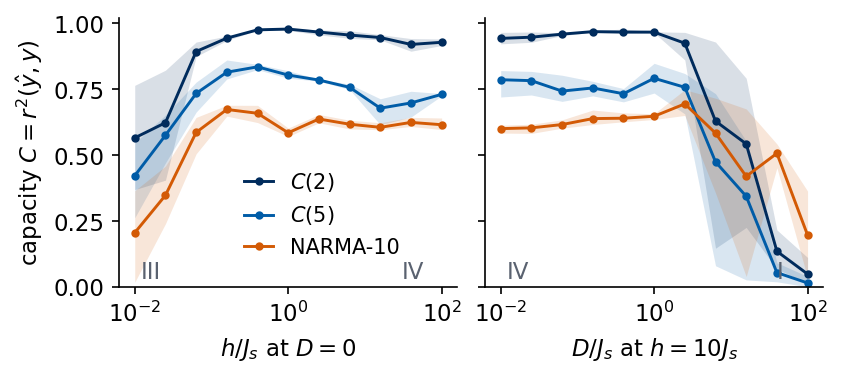

In [17]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), sharey=True, layout="constrained")
    for ax, sc, xl in ((axs[0], scan_h, r"$h/J_s$ at $D=0$"), (axs[1], scan_W, rf"$D/J_s$ at $h={H_W:g}J_s$")):
        for col, (lab, y) in zip((UJNavy, UJBlue, DSOrange),
                                 ((r"$C(2)$", sc[:, :, 1]), (r"$C(5)$", sc[:, :, 4]), ("NARMA-10", sc[:, :, D_MAX + 1]))):
            ax.plot(SCAN, y.mean(1), color=col, marker="o", ms=3, label=lab)
            ax.fill_between(SCAN, y.min(1), y.max(1), color=col, alpha=0.15, lw=0)
        ax.set_xscale("log"); ax.set_xlabel(xl); ax.set_ylim(0, 1.02); ax.set_xticks([1e-2, 1, 1e2])
    axs[0].set_ylabel(r"capacity $C=r^2(\tilde y,y)$")
    axs[0].text(0.012, 0.03, "III", fontsize=11, color=UJGray); axs[0].text(30, 0.03, "IV", fontsize=11, color=UJGray)
    axs[1].text(0.012, 0.03, "IV", fontsize=11, color=UJGray); axs[1].text(40, 0.03, "I", fontsize=11, color=UJGray)
    axs[0].legend(loc="lower center", bbox_to_anchor=(0.6, 0.04), fontsize=10, handlelength=1.4)
    save(fig, "fig_lab047_capacity_phases"); plt.show()

The capacity follows the regimes of the level statistics. Along the field cut it is lowest at $h=0.01J_s$, in the spin-glass region, rises steeply between $h=0.01J_s$ and $h=0.16J_s$, where $\langle r\rangle$ rises from the Poisson towards the GOE value, and reaches its largest memory capacity, $\mathrm{MC}=12.7$, at $h=0.063J_s$. Deeper in the ergodic region the memory capacity falls to about $6$, while $C(5)$ and NARMA-10 stay at about $0.7$ and $0.6$. Along the disorder cut all scores stay flat up to $D\approx J_s$, the memory capacity peaks at $D=2.5J_s$ with $\mathrm{MC}=10.4$, near the onset of localisation in the map, and all scores fall above $D\approx6J_s$, down to a memory capacity of $0.98$ at $D=100J_s$. This reproduces at $N=6$ the qualitative result of the published study, low capacity in the spin-glass and localised regimes and the best memory in the ergodic regime near its border. The positions of the maxima are known only to the grid spacing, a factor $2.5$, and they may shift with $N$.

For a classical reference we use an ESN with as many neurons as the quantum reservoir has features, $n=63$. Its state follows
$$
\mathbf r_k=(1-\alpha)\,\mathbf r_{k-1}+\alpha\tanh\big(W\mathbf r_{k-1}+\mathbf w_{\rm in}s_k\big),
$$
with a sparse random matrix $W$ of spectral radius $\rho$, input weights $\mathbf w_{\rm in}$ uniform in $[-\sigma_{\rm in},\sigma_{\rm in}]$ and leak rate $\alpha$. We choose $(\rho,\sigma_{\rm in},\alpha)$ from a grid of $24$ settings by the validation memory capacity and use the same readout and data split as for the quantum reservoir. We then compare the memory curves $C(d)$ of the quantum reservoir in the three regimes, at the field of largest memory capacity and of the ESN.

In [18]:
def esn_base(n, seed, density=0.1):
    # random sparse W rescaled to spectral radius 1 and input weights uniform in [-1, 1]; scaled later by rho, sigma_in
    rng = np.random.default_rng(seed)
    W = rng.normal(size=(n, n)) * (rng.random((n, n)) < density)
    W /= np.max(np.abs(np.linalg.eigvals(W)))
    return W, rng.uniform(-1.0, 1.0, size=n)

@jax.jit
def esn_states(W, w_in, u, alpha, x0):
    # r_k = (1 - alpha) r_{k-1} + alpha tanh(W r_{k-1} + w_in u_k), returns all states (T, n)
    def step(x, uk):
        x = (1.0 - alpha) * x + alpha * jnp.tanh(W @ x + w_in * uk)
        return x, x
    return jax.lax.scan(step, x0, u)[1]

N_ESN = M_FEAT                                    # as many neurons as the quantum reservoir has features
ESN_GRID = [(r, si, a) for r in (0.5, 0.8, 0.95, 1.1) for si in (0.1, 0.5, 1.0) for a in (0.3, 1.0)]
W_esn, w_esn = esn_base(N_ESN, seed=0)
best = (-1.0, None)
for (r, si, a) in ESN_GRID:
    X = np.asarray(esn_states(r * W_esn, si * w_esn, s_mem_j, a, jnp.zeros(N_ESN)))
    ct, cv = capacities(X, Y_all)
    if cv[:D_MAX].sum() > best[0]:
        best = (cv[:D_MAX].sum(), dict(rho=r, sigma_in=si, alpha=a, C=ct))
esn_mem = best[1]
print(f"ESN with {N_ESN} neurons, best by validation MC: rho = {esn_mem['rho']}, sigma_in = {esn_mem['sigma_in']},"
      f" alpha = {esn_mem['alpha']}: test MC = {esn_mem['C'][:D_MAX].sum():.2f}, NARMA-2 C = {esn_mem['C'][D_MAX]:.3f},"
      f" NARMA-10 C = {esn_mem['C'][D_MAX + 1]:.3f}")

# memory curves of the quantum reservoir in the three regimes and at the largest MC of the D = 0 scan
curves = {name: qrc_scores(p["h"], p["W"]) for name, p in REG.items()}
curves["border"] = scan_h[np.argmax(MC(scan_h).mean(1))]
nums["memory"] = {name: dict(MC=float(MC(c).mean()), MC_sd=float(MC(c).std()), narma2=float(c[:, D_MAX].mean()),
                             narma10=float(c[:, D_MAX + 1].mean())) for name, c in curves.items()}
nums["memory"]["ESN"] = dict(MC=float(esn_mem["C"][:D_MAX].sum()), narma2=float(esn_mem["C"][D_MAX]),
                             narma10=float(esn_mem["C"][D_MAX + 1]), rho=esn_mem["rho"], sigma_in=esn_mem["sigma_in"],
                             alpha=esn_mem["alpha"])
for name, v in nums["memory"].items():
    print(f"{name:10s} MC = {v['MC']:6.2f}   NARMA-2 C = {v['narma2']:.3f}   NARMA-10 C = {v['narma10']:.3f}")

ESN with 63 neurons, best by validation MC: rho = 0.95, sigma_in = 0.1, alpha = 1.0: test MC = 24.70, NARMA-2 C = 0.886, NARMA-10 C = 0.863


ergodic    MC =   6.06   NARMA-2 C = 0.963   NARMA-10 C = 0.599
spin glass MC =   8.20   NARMA-2 C = 0.407   NARMA-10 C = 0.205
localised  MC =   0.29   NARMA-2 C = 0.028   NARMA-10 C = 0.091
border     MC =  12.73   NARMA-2 C = 0.765   NARMA-10 C = 0.586
ESN        MC =  24.70   NARMA-2 C = 0.886   NARMA-10 C = 0.863


The figure shows $C(d)$ against the delay $d$, averaged over the $3$ draws for the quantum reservoir, and the legend gives the memory capacity of each curve.

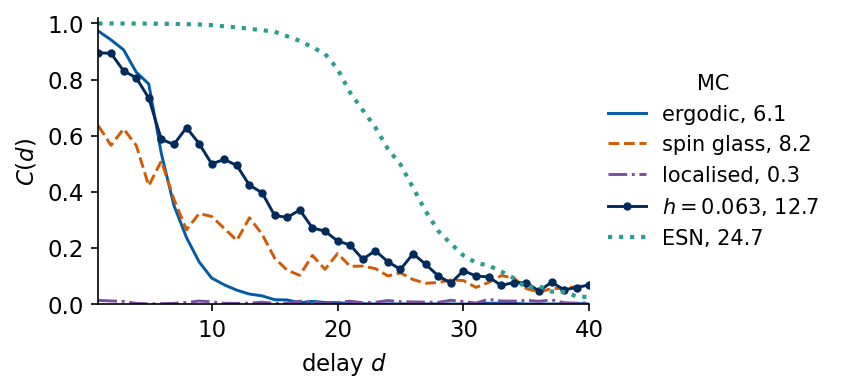

In [19]:
d_ax = np.arange(1, D_MAX + 1)
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.5), layout="constrained")
    for name, p in REG.items():
        ax.plot(d_ax, curves[name][:, :D_MAX].mean(0), color=p["color"], ls=p["ls"],
                label=f"{name}, {nums['memory'][name]['MC']:.1f}")
    ax.plot(d_ax, curves["border"][:, :D_MAX].mean(0), color=UJNavy, marker="o", ms=3,
            label=f"$h={H_BEST:.2g}$, {nums['memory']['border']['MC']:.1f}")
    ax.plot(d_ax, esn_mem["C"][:D_MAX], color=ESN_COLOR, ls=":", lw=2, label=f"ESN, {nums['memory']['ESN']['MC']:.1f}")
    ax.set_xlim(1, D_MAX); ax.set_ylim(0, 1.02); ax.set_xlabel("delay $d$"); ax.set_ylabel("$C(d)$")
    ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=10, handlelength=1.8, title="MC", title_fontsize=10)
    save(fig, "fig_lab047_memory_curves"); plt.show()

In the ergodic regime the recall is almost perfect for $d\le3$ and drops to zero after about $15$ steps, with $\mathrm{MC}=6.1$. Near the border at $h=0.063J_s$ the curve starts lower but decays more slowly, and the memory capacity doubles to $12.7$. In the spin-glass regime the recall is reduced already at $d=1$, with $C(1)\approx0.6$, and in the localised regime it is absent, $\mathrm{MC}=0.3$, because the input remains on qubit 1 and is erased at the next reset. The tuned ESN with $63$ neurons reaches $\mathrm{MC}=24.7$, about twice the best quantum value, and also scores higher on NARMA-10, $0.86$ against $0.59$ for the quantum reservoir at the border and $0.60$ in the ergodic regime. On NARMA-2 the ergodic quantum reservoir scores $0.96$ and the ESN $0.89$. With the same number of features the six-qubit reservoir therefore stores fewer past inputs than the tuned classical one. A sum to $d=40$ includes small contributions of order $0.05$ per delay at large $d$ for the slowly forgetting reservoirs, which are part of the reported values.

In these runs both the training and the test data come from one long run started from the maximally mixed state, so a reservoir without the echo state property still gives reproducible features. Its readout depends on the initial state, though. We make this visible by fitting the readout on a run from $\hat I/2^N$ (run A) and applying it to a run of the same reservoir with the same inputs started from a random pure state (run B).

In [20]:
@jax.jit
def qrc_features_from(h, W, key, s, rho0):
    # the same reservoir and inputs, started from the density matrix rho0
    return run_reservoir(unitary(hamiltonian(N, h, W, key), DT), s, 0.0, rho0)

def transfer_capacities(F_a, F_b, Y):
    # readout fitted on run A (ridge strength from the validation block of A), applied to the test block of run B
    best_v, best_t = np.full(Y.shape[1], -1.0), np.zeros(Y.shape[1])
    for beta in BETAS:
        W, b = ridge_fit(F_a[TR], Y[TR], beta)
        cv, ct = r2(F_a[VA] @ W + b, Y[VA]), r2(F_b[TE] @ W + b, Y[TE])
        better = cv > best_v
        best_v[better], best_t[better] = cv[better], ct[better]
    return best_t

N_REAL_TR = 2
nums["transfer"] = {}
for name, p in REG.items():
    mc_same, mc_tr = [], []
    for r_ in range(N_REAL_TR):
        phi = jax.random.normal(jax.random.key(60 + r_), (DIM,)) + 1j * jax.random.normal(jax.random.key(70 + r_), (DIM,))
        phi = phi / jnp.linalg.norm(phi)                         # random pure initial state of run B
        F_a = np.asarray(qrc_features(p["h"], p["W"], keys_mem[r_], s_mem_j, 0.0, DT))
        F_b = np.asarray(qrc_features_from(p["h"], p["W"], keys_mem[r_], s_mem_j, jnp.outer(phi, phi.conj())))
        mc_same.append(capacities(F_a, Y_delay)[0].sum()); mc_tr.append(transfer_capacities(F_a, F_b, Y_delay).sum())
        if r_ == 0:
            nums["transfer"][name] = dict(feat_diff_test=float(np.abs(F_a[TE] - F_b[TE]).max()))
    nums["transfer"][name].update(MC_same=float(np.mean(mc_same)), MC_transfer=float(np.mean(mc_tr)))
    print(f"{name:10s} max |x_A - x_B| on the test block {nums['transfer'][name]['feat_diff_test']:.1e};"
          f" MC with the readout of run A: on run A {np.mean(mc_same):.2f}, on run B {np.mean(mc_tr):.2f}")

ergodic    max |x_A - x_B| on the test block 8.3e-16; MC with the readout of run A: on run A 5.98, on run B 5.98


spin glass max |x_A - x_B| on the test block 2.6e-01; MC with the readout of run A: on run A 7.95, on run B 0.04


localised  max |x_A - x_B| on the test block 2.8e-01; MC with the readout of run A: on run A 0.34, on run B 0.07


In the ergodic regime the features of the two runs agree to $7.8\times10^{-16}$ on the test block, and the readout of run A gives the same memory capacity on both runs, $5.98$ on average over $2$ draws. In the spin-glass regime the features differ by up to $0.26$, and the memory capacity falls from $7.95$ on run A to $0.04$ on run B. In the localised regime it falls from $0.34$ to $0.07$. A readout trained on a reservoir without the echo state property works only for the initial state used in training, and the moderate memory capacity found above in the spin-glass regime is of this kind. In an experiment, where the initial state is never controlled perfectly, such a reservoir is of little use.

<hr/>
## 6. Forecasting the Santa Fe laser

We now forecast a measured signal, the intensity of a far-infrared laser in a chaotic state, recorded for the Santa Fe time-series competition [A. S. Weigend, N. A. Gershenfeld (eds.), *Time Series Prediction*, Addison-Wesley (1994), reprinted by Routledge (2018), [doi:10.4324/9780429492648](https://doi.org/10.4324/9780429492648)]. We use the first $4000$ samples, rescale them to $[0,1]$ with the minimum and maximum of the first $3000$, and clip the values to $[0,1]$ before encoding. From every forecast origin $k$ one readout predicts the values $s_{k+\tau}$ for all leads $\tau=1,\dots,50$ from the features at step $k$, and the score at each lead is $C(\tau)=r^2(\tilde s_{k+\tau},s_{k+\tau})$ over the test origins. The origins $63$ to $2449$ are used for fitting, $2499$ to $2949$ for validation and $2999$ to $3949$ for testing.

We compare four forecasters. Persistence repeats the last value. A linear autoregressive (AR) model uses the $63$ most recent values. The ESN has $63$ neurons, and the quantum reservoir has $63$ features. For the ESN we choose the setting from the same grid of $24$ settings, and for the quantum reservoir the field $h\in\{0.1,1,10\}J_s$ and the step $J_s\Delta t\in\{1,3,10\}$, with $D=0$ and one draw of the couplings, by the validation score $C_{\rm tot}=\sum_{\tau=1}^{50}C(\tau)$.

In [21]:
N_SAMPLES, N_TRAIN, N_VAL, TAU_MAX = 4000, 3000, 500, 50
raw_sf = np.loadtxt("../../Lecture_8/Notebooks/data/santafe_laser.txt").astype(float)[:N_SAMPLES]
lo, hi = raw_sf[:N_TRAIN].min(), raw_sf[:N_TRAIN].max()
s_sf = (raw_sf - lo) / (hi - lo)                    # [0, 1] on the training block
K_FIT = np.arange(63, N_TRAIN - N_VAL - TAU_MAX)     # forecast origins for fitting, validation and test
K_VAL = np.arange(N_TRAIN - N_VAL - 1, N_TRAIN - TAU_MAX)
K_TEST = np.arange(N_TRAIN - 1, N_SAMPLES - TAU_MAX)
TAUS = np.arange(1, TAU_MAX + 1)
Y_sf = {nm: s_sf[ks[:, None] + TAUS[None, :]] for nm, ks in (("fit", K_FIT), ("val", K_VAL), ("test", K_TEST))}
print(f"Santa Fe: {N_SAMPLES} samples, test range [{s_sf[N_TRAIN:].min():.3f}, {s_sf[N_TRAIN:].max():.3f}];"
      f" origins fit {len(K_FIT)}, validation {len(K_VAL)}, test {len(K_TEST)}")

def fit_forecaster(F):
    # one ridge readout for all leads tau = 1..50; ridge strength chosen by the validation C_tot
    best = (-1.0, None)
    for beta in BETAS:
        W, b = ridge_fit(F[K_FIT], Y_sf["fit"], beta)
        cv = r2(F[K_VAL] @ W + b, Y_sf["val"]).sum()
        if cv > best[0]:
            best = (cv, (W, b, beta))
    W, b, beta = best[1]
    pred = F[K_TEST] @ W + b
    C_t = r2(pred, Y_sf["test"])
    return dict(val=best[0], C=C_t, Ctot=float(C_t.sum()), pred=pred, beta=beta)

t0 = time.time()
sf_res = {}
p_sf = np.repeat(s_sf[K_TEST][:, None], TAU_MAX, 1)
sf_res["persistence"] = dict(C=r2(p_sf, Y_sf["test"]), pred=p_sf)
sf_res["persistence"]["Ctot"] = float(sf_res["persistence"]["C"].sum())
F_ar = s_sf[np.arange(N_SAMPLES)[:, None] - np.arange(M_FEAT)[None, :]]     # s_k, ..., s_{k-62}, as many as QRC features
sf_res["AR"] = fit_forecaster(F_ar)
best = None
for (r, si, a) in ESN_GRID:
    out = fit_forecaster(np.asarray(esn_states(r * W_esn, si * w_esn, jnp.asarray(s_sf), a, jnp.zeros(N_ESN))))
    if best is None or out["val"] > best["val"]:
        best = dict(out, rho=r, sigma_in=si, alpha=a)
sf_res["ESN"] = best
best = None
s_in = jnp.asarray(np.clip(s_sf, 0, 1))           # the encoding needs s in [0, 1]
for h in (0.1, 1.0, 10.0):
    for dt in (1.0, 3.0, 10.0):
        out = fit_forecaster(np.asarray(qrc_features(h, 0.0, keys_mem[0], s_in, 0.0, dt)))
        if best is None or out["val"] > best["val"]:
            best = dict(out, h=h, dt=dt)
sf_res["QRC"] = best
print(f"Santa Fe forecasters: {time.time() - t0:.0f} s")
for m, v in sf_res.items():
    extra = {"ESN": f"rho = {v.get('rho')}, sigma_in = {v.get('sigma_in')}, alpha = {v.get('alpha')}",
             "QRC": f"h = {v.get('h')}, J_s dt = {v.get('dt')}"}.get(m, "")
    print(f"{m:12s} C_tot = {v['Ctot']:5.1f}   C(1) = {v['C'][0]:.3f}   C(5) = {v['C'][4]:.3f}   C(10) = {v['C'][9]:.3f}   {extra}")
nums["santafe"] = {m: dict(Ctot=v["Ctot"], C1=float(v["C"][0]), C5=float(v["C"][4]), C10=float(v["C"][9]),
                          C=[float(x) for x in v["C"]]) for m, v in sf_res.items()}     # C: tau = 1..50
nums["santafe"]["QRC"].update(h=sf_res["QRC"]["h"], dt=sf_res["QRC"]["dt"])
nums["santafe"]["ESN"].update(rho=sf_res["ESN"]["rho"], sigma_in=sf_res["ESN"]["sigma_in"], alpha=sf_res["ESN"]["alpha"])

Santa Fe: 4000 samples, test range [0.004, 1.000]; origins fit 2387, validation 451, test 951


Santa Fe forecasters: 26 s
persistence  C_tot =   5.5   C(1) = 0.269   C(5) = 0.193   C(10) = 0.098   
AR           C_tot =  16.4   C(1) = 0.847   C(5) = 0.767   C(10) = 0.596   
ESN          C_tot =  26.5   C(1) = 0.962   C(5) = 0.894   C(10) = 0.739   rho = 0.95, sigma_in = 0.5, alpha = 1.0
QRC          C_tot =  24.4   C(1) = 0.992   C(5) = 0.876   C(10) = 0.792   h = 1.0, J_s dt = 10.0


The left panel shows the test target $s_{k+5}$ and the forecast $\tilde s_{k+5}$ of the quantum reservoir over the first $120$ test origins. The right panel shows $C(\tau)$ against the lead $\tau$ for the four forecasters.

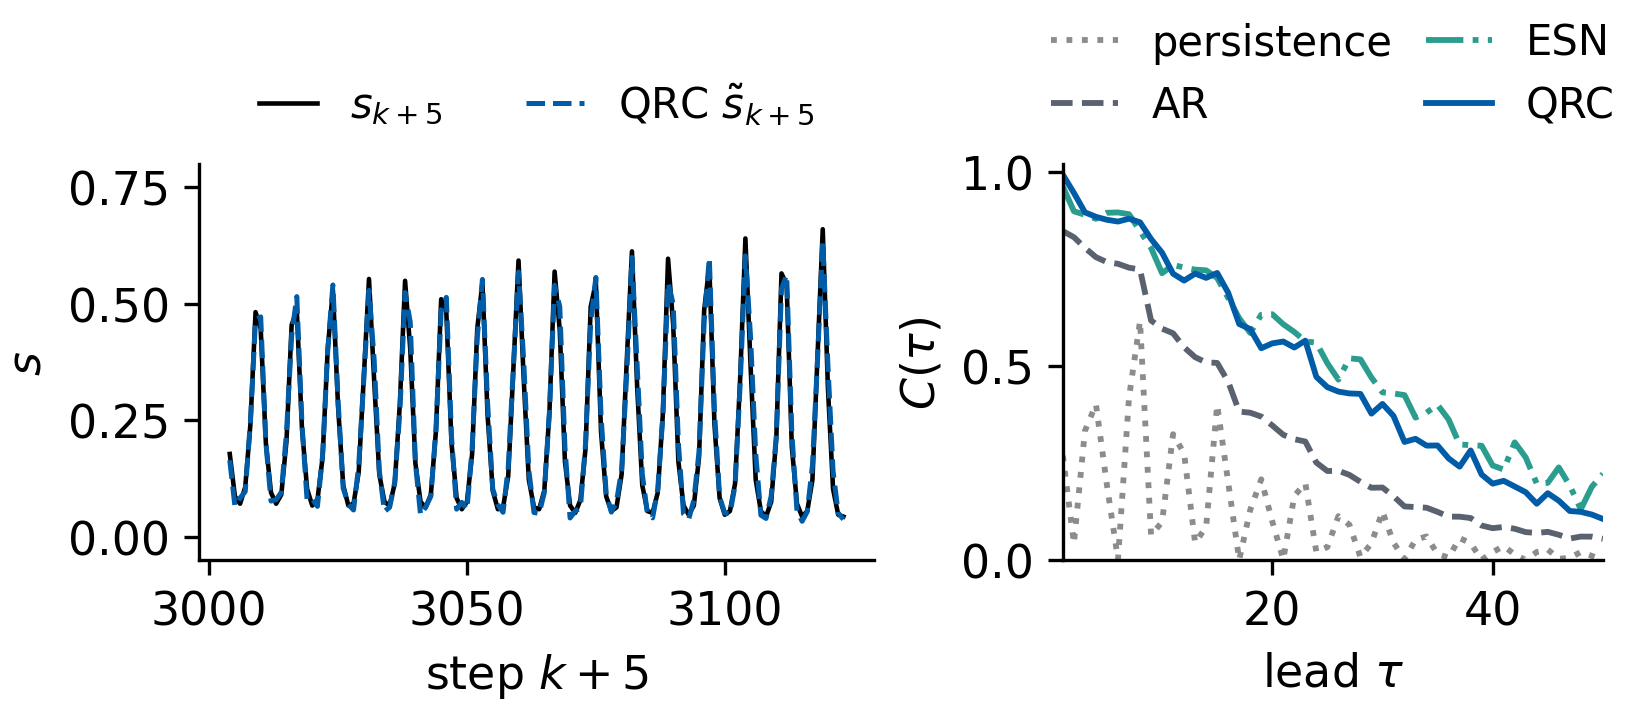

In [22]:
SF_STYLE = {"persistence": dict(color="0.55", ls=":"), "AR": dict(color=UJGray, ls="--"),
            "ESN": dict(color=ESN_COLOR, ls="-."), "QRC": dict(color=UJBlue, ls="-")}
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), layout="constrained", gridspec_kw={"width_ratios": [1.25, 1.0]})
    ax, t_show, n_show = axs[0], 5, 120
    kk = K_TEST[:n_show] + t_show
    ax.plot(kk, Y_sf["test"][:n_show, t_show - 1], color="k", lw=1.1, label=r"$s_{k+5}$")
    ax.plot(kk, sf_res["QRC"]["pred"][:n_show, t_show - 1], color=UJBlue, ls="--", lw=1.2, label=r"QRC $\tilde s_{k+5}$")
    ax.set_xlabel(r"step $k+5$"); ax.set_ylabel("$s$"); ax.set_ylim(-0.05, 0.8)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=10, handlelength=1.4)
    ax = axs[1]
    for m, st in SF_STYLE.items():
        ax.plot(TAUS, sf_res[m]["C"], label=m, **st)
    ax.set_xlim(1, TAU_MAX); ax.set_ylim(0, 1.02); ax.set_xlabel(r"lead $\tau$"); ax.set_ylabel(r"$C(\tau)$")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=10, handlelength=1.6, columnspacing=0.8)
    save(fig, "fig_lab047_santafe"); plt.show()

Validation selects $h=J_s$ and $J_s\Delta t=10$, a point where $\langle r\rangle$ of the six-qubit register is close to the GOE value. The quantum reservoir has the best one-step score, $C(1)=0.992$, against $0.962$ for the ESN and $0.847$ for the AR model, and it reaches $C_{\rm tot}=24.4$. The ESN reaches $C_{\rm tot}=26.5$, with higher scores than the quantum reservoir at most leads beyond about $25$ steps, the AR model reaches $16.4$ and persistence $5.5$. Both reservoirs clearly beat the linear model with the same number of inputs, and the two reservoirs are close to each other. These numbers come from one draw of the couplings and a grid of nine settings, and their uncertainty is unquantified. They show two reservoirs of similar forecasting quality on this signal.

<hr/>
## 7. Measurement and back-action

So far the features were exact expectation values. In an experiment each $\langle \hat P_\alpha\rangle$ is estimated from $N_{\rm meas}$ repetitions (shots), and a projective measurement collapses the state and erases the memory held in the register. The features of a series of $K$ steps can then be obtained in three ways [P. Mujal, R. Martínez-Peña, G. L. Giorgi, M. C. Soriano, R. Zambrini, npj Quantum Inf. **9**, 16 (2023), [doi:10.1038/s41534-023-00682-z](https://doi.org/10.1038/s41534-023-00682-z)]. In the restart protocol the register is prepared anew for every $k$, fed with $s_1,\dots,s_k$ and measured, which costs $K(K+1)/2$ steps for one shot at every $k$. In the rewind protocol only the last $N_{\rm wo}$ inputs are fed, which is enough when the echo state property holds and costs $KN_{\rm wo}$ steps. In the online protocol the register runs once through the whole series and is measured weakly after every step, which costs $K$ steps.

A weak measurement of qubit $i$ couples it to a probe whose readout is $V_i=g\,z_i+\xi_i$, with $z_i=\pm1$ for $|0\rangle$ and $|1\rangle$, Gaussian noise $\xi_i$ of unit variance and measurement strength $g$. Its Kraus operator for the outcome $V$ is
$$
\hat\Omega_V=(2\pi)^{-1/4}\Big[e^{-(V-g)^2/4}|0\rangle\langle0|+e^{-(V+g)^2/4}|1\rangle\langle1|\Big],
$$
so that $V$ has a Gaussian distribution centred at $+g$ or $-g$. Averaged over the outcomes the populations stay unchanged and the coherence of the measured qubit shrinks, $\rho_{01}\to e^{-g^2/2}\rho_{01}$. For all qubits measured after every step the averaged dynamics is
$$
\hat\rho_k=\Gamma\odot\mathcal T_{s_k}(\hat\rho_{k-1}),\qquad \Gamma_{ab}=e^{-g^2 n_{ab}/2},
$$
where $\odot$ is the element-wise product and $n_{ab}$ is the number of qubits in which the basis states $a$ and $b$ differ [G. Franceschetto, M. Płodzień, M. Lewenstein, A. Acín, P. Mujal, Phys. Rev. X **16**, 021002 (2026), [doi:10.1103/j7f9-hfsj](https://doi.org/10.1103/j7f9-hfsj)]. The weak measurement acts on average as a dephasing channel, an additional source of forgetting set by $g$, and $g\to0$ recovers the undisturbed reservoir of the restart protocol. The expectation values follow from averages of the readouts, $\langle \hat Z_i\rangle=\langle V_i\rangle/g$ and $\langle \hat Z_i\hat Z_j\rangle=\langle V_iV_j\rangle/g^2$ for $i\ne j$, so the online protocol gives the $21$ features $\hat Z_i$ and $\hat Z_i\hat Z_j$.

We check the averaged back-action by numerical integration over $V$ and compute two numbers of the protocol comparison. Per shot the estimate of $\langle \hat Z\rangle$ has variance $1-\langle \hat Z\rangle^2$ for a projective measurement and $\big(1+g^2(1-\langle \hat Z\rangle^2)\big)/g^2$ for the weak one.

In [23]:
# averaged back-action of the weak measurement on one qubit, by numerical integration over the outcome V
g = 0.3
V = np.linspace(-14, 14, 20001)
w0 = (2 * np.pi) ** -0.25 * np.exp(-(V - g) ** 2 / 4)          # diagonal of the Kraus operator Omega_V
w1 = (2 * np.pi) ** -0.25 * np.exp(-(V + g) ** 2 / 4)
norm00, norm11 = np.trapezoid(w0 ** 2, V), np.trapezoid(w1 ** 2, V)
coh = np.trapezoid(w0 * w1, V)
mean_V0 = np.trapezoid(V * w0 ** 2, V)
print(f"int Omega^dag Omega dV = diag({norm00:.12f}, {norm11:.12f}); coherence factor {coh:.12f}, exp(-g^2/2) = {np.exp(-g**2 / 2):.12f};"
      f" <V> for |0> = {mean_V0:.6f} = g")
# noise of the estimators of <Z> per shot at <Z> = 0: projective sqrt(1 - <Z>^2), weak sqrt(1 + g^2 (1 - <Z>^2)) / g
ratio = np.sqrt(1 + g ** 2) / g
K_COST, N_WO = 2000, 20
nums["backaction_check"] = dict(g=g, coh=float(coh), sigma_ratio=float(ratio), shot_factor=float(ratio ** 2),
                                restart_steps=K_COST * (K_COST + 1) // 2, rewind_steps=K_COST * N_WO, online_steps=K_COST)
print(f"g = {g}: error ratio weak / projective at <Z> = 0: {ratio:.2f}, so {ratio ** 2:.1f} times more shots for equal error")
print(f"K = {K_COST}: restart needs {K_COST * (K_COST + 1) // 2} steps per shot of the whole series, rewind with N_wo = {N_WO}"
      f" needs {K_COST * N_WO}, online needs {K_COST}")

int Omega^dag Omega dV = diag(1.000000000000, 1.000000000000); coherence factor 0.955997481833, exp(-g^2/2) = 0.955997481833; <V> for |0> = 0.300000 = g
g = 0.3: error ratio weak / projective at <Z> = 0: 3.48, so 12.1 times more shots for equal error
K = 2000: restart needs 2001000 steps per shot of the whole series, rewind with N_wo = 20 needs 40000, online needs 2000


The Kraus operators are complete, $\int\hat\Omega_V^\dagger\hat\Omega_V\,dV=\hat I$, and the coherence factor equals $e^{-g^2/2}$ to twelve digits. At $g=0.3$ and $\langle \hat Z\rangle=0$ the error per shot of the weak measurement is $3.48$ times that of the projective one, so equal precision needs $12.1$ times more shots. For a series of $K=2000$ steps the restart protocol needs $2001000$ steps for one shot at every $k$ and the online protocol $2000$, so in equal time the online protocol collects about $1000$ times more shots, which more than compensates its larger error per shot.

We now compare the memory capacity of the online protocol at strength $g$ with that of the restart protocol, both with exact expectation values of the $21$ features $\hat Z_i$ and $\hat Z_i\hat Z_j$, on a grid of $7$ fields from $0.01J_s$ to $10J_s$ at $D=0$ and $5$ strengths, with $2$ draws. The ratio $P_R(g,h)=\mathrm{MC}^{\rm online}(g,h)/\mathrm{MC}^{\rm restart}(h)$ measures the gain from the back-action.

In [24]:
t0 = time.time()
H_BA = np.logspace(-2, 1, 7)
G_BA = (0.0, 0.1, 0.2, 0.3, 0.5, 1.0)
N_REAL_BA = 2
mc_ba = np.array([[MC(qrc_scores(h, 0.0, g=g, n_real=N_REAL_BA, zonly=True)).mean() for g in G_BA] for h in H_BA])
P_R = mc_ba[:, 1:] / mc_ba[:, :1]
print(f"online versus restart, {len(H_BA)} x {len(G_BA)} points x {N_REAL_BA} draws, Z features only: {time.time() - t0:.0f} s")
print("h      " + "".join(f"   g={g:<4}" for g in G_BA))
for h, row in zip(H_BA, mc_ba):
    print(f"{h:<7.3g}" + "".join(f"{x:9.2f}" for x in row))
i_max = np.unravel_index(np.argmax(P_R), P_R.shape)
nums["backaction"] = dict(h=H_BA.tolist(), g=list(G_BA), MC=mc_ba.tolist(), PR_max=float(P_R.max()),
                          PR_max_h=float(H_BA[i_max[0]]), PR_max_g=float(G_BA[1:][i_max[1]]), PR_min=float(P_R.min()),
                          best_restart=float(mc_ba[:, 0].max()), best_online=float(mc_ba[:, 1:].max()))
print(f"largest P_R = {P_R.max():.2f} at h = {H_BA[i_max[0]]:g}, g = {G_BA[1:][i_max[1]]}; smallest {P_R.min():.2f};"
      f" best MC restart {mc_ba[:, 0].max():.2f}, best online {mc_ba[:, 1:].max():.2f}")

online versus restart, 7 x 6 points x 2 draws, Z features only: 129 s
h         g=0.0    g=0.1    g=0.2    g=0.3    g=0.5    g=1.0 
0.01        5.58     8.50     8.84     7.77     5.34     2.92
0.0316      7.84     9.86    10.39     9.55     7.45     4.45
0.1         7.82     8.44     8.33     7.79     6.29     4.22
0.316       5.66     5.60     5.43     5.19     4.73     3.93
1           4.46     4.44     4.38     4.31     4.19     3.77
3.16        4.32     4.30     4.26     4.18     3.91     3.36
10          3.86     3.84     3.79     3.70     3.47     3.00
largest P_R = 1.58 at h = 0.01, g = 0.2; smallest 0.52; best MC restart 7.84, best online 10.39


The left panel shows $\log_2P_R$ over the measurement strength $g$ and the field $h/J_s$, red for a gain and blue for a loss. The right panel shows the memory capacity with the $\hat Z$ features against $h/J_s$ for the restart protocol (solid) and for the online protocol at three strengths (dashed).

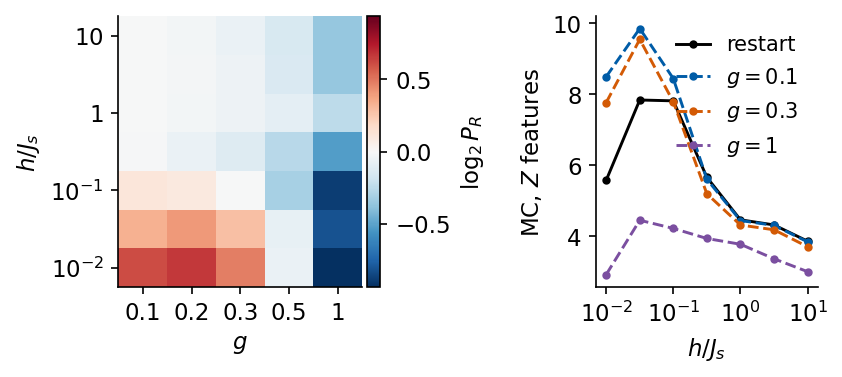

In [25]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), layout="constrained", gridspec_kw={"width_ratios": [1.1, 1.0]})
    ax = axs[0]
    vmax = max(abs(np.log2(P_R)).max(), 0.1)
    pc = ax.pcolormesh(np.arange(len(G_BA) - 1), np.log10(H_BA), np.log2(P_R), cmap="RdBu_r", vmin=-vmax, vmax=vmax, shading="nearest")
    cb = fig.colorbar(pc, ax=ax, pad=0.02); cb.set_label(r"$\log_2 P_R$")
    ax.set_xticks(np.arange(len(G_BA) - 1), [f"{g:g}" for g in G_BA[1:]]); ax.set_xlabel("$g$")
    ax.set_yticks([-2, -1, 0, 1], ["$10^{-2}$", "$10^{-1}$", "$1$", "$10$"]); ax.set_ylabel(r"$h/J_s$")
    ax = axs[1]
    for g, col in zip((0.0, 0.1, 0.3, 1.0), ("k", UJBlue, DSOrange, "#7B4FA0")):
        ax.plot(H_BA, mc_ba[:, G_BA.index(g)], color=col, marker="o", ms=3, ls="-" if g == 0 else "--",
                label="restart" if g == 0 else f"$g={g:g}$")
    ax.set_xscale("log"); ax.set_xlabel(r"$h/J_s$"); ax.set_ylabel(r"MC, $\hat Z$ features"); ax.set_xticks([1e-2, 1e-1, 1, 10])
    ax.legend(loc="upper right", fontsize=10, handlelength=1.6)
    fig.get_layout_engine().set(wspace=0.08)
    save(fig, "fig_lab047_backaction"); plt.show()

The back-action helps where the reservoir forgets too slowly. At small fields, in the spin-glass region and at its border, a weak measurement with $g\le0.3$ raises the memory capacity, with the largest ratio $P_R=1.58$ at $h=0.01J_s$ and $g=0.2$. The best online value over the grid, $\mathrm{MC}=10.4$, exceeds the best restart value, $7.8$. At larger fields, where the register already forgets fast, the extra dephasing reduces the memory capacity, and a strong measurement, $g=1$, reduces it everywhere, down to $P_R=0.52$. An intermediate strength is therefore best, which agrees with the trend reported by Franceschetto *et al.* for a transverse-field Ising chain. Our grid has $2$ draws and $N=6$, so the values of $P_R$ are indicative.

Finally we include a finite number of shots. We model the estimate of every feature at every step as its exact value plus an independent Gaussian error with the variance per shot given above divided by the number of shots. For products $\hat Z_i\hat Z_j$ in the online protocol the variance of $V_iV_j/g^2$ per shot is $\big((1+g^2)^2-g^4\langle \hat Z_i\hat Z_j\rangle^2\big)/g^4$. Independence of the errors at different steps is an approximation for the online protocol, where one shot is a whole trajectory. We take the field of the largest restart memory capacity on the grid, $h=0.032J_s$, and $g=0.3$, and compare three cases, the restart protocol with $N_{\rm meas}$ shots per step, the online protocol with the same $N_{\rm meas}$, and the online protocol in the same total time, with $K/2=1500$ times more shots for our series of $K=3000$ steps. The ridge strength is chosen from a wider range of values, since noisy features need stronger regularisation.

In [26]:
# finite numbers of shots N_meas: Gaussian errors added to every feature at every step, independently
h_sh, g_sh = float(H_BA[np.argmax(mc_ba[:, 0])]), 0.3
X_rs = np.asarray(qrc_features(h_sh, 0.0, keys_mem[0], s_mem_j, 0.0, DT))[:, IS_Z]
X_ol = np.asarray(qrc_features(h_sh, 0.0, keys_mem[0], s_mem_j, g_sh, DT))[:, IS_Z]
one_q = np.array([len(qs) == 1 for qs, a in STRINGS if a == "Z"])
def sd_restart(X):
    # projective measurement of a Pauli string: variance 1 - <P>^2 per shot
    return np.sqrt(np.clip(1 - X ** 2, 0, None))
def sd_online(X, g):
    # V_i = g z_i + xi_i: Var(V_i / g) = (1 + g^2 (1 - <Z>^2)) / g^2, Var(V_i V_j / g^2) = ((1 + g^2)^2 - g^4 <ZZ>^2) / g^4
    return np.where(one_q, np.sqrt(1 + g ** 2 * (1 - X ** 2)) / g, np.sqrt((1 + g ** 2) ** 2 - g ** 4 * X ** 2) / g ** 2)
NMEAS = np.logspace(2, 8, 13)
BETAS_NOISY = (1e-6, 1e-4, 1e-2, 1.0, 1e2)          # noisy features need stronger regularisation
print(f"standard deviation over time of the Z features: median {np.median(X_rs[TR].std(0)):.1e} (restart),"
      f" {np.median(X_ol[TR].std(0)):.1e} (online, g = {g_sh})")
FAC = K_TOT / 2                                    # shots per unit time, online over restart, for K = K_TOT
rng = np.random.default_rng(9)
mc_sh = {"restart": [], "online, equal shots": [], "online, equal time": []}
for nm in NMEAS:
    for lab, X, sd, n_eff in (("restart", X_rs, sd_restart(X_rs), nm), ("online, equal shots", X_ol, sd_online(X_ol, g_sh), nm),
                               ("online, equal time", X_ol, sd_online(X_ol, g_sh), nm * FAC)):
        Xn = X + sd / np.sqrt(n_eff) * rng.normal(size=X.shape)
        mc_sh[lab].append(capacities(Xn, Y_delay, BETAS_NOISY)[0].sum())
mc_inf = {"restart": capacities(X_rs, Y_delay)[0].sum(), "online": capacities(X_ol, Y_delay)[0].sum()}
nums["shots"] = dict(feat_sd_restart=float(np.median(X_rs[TR].std(0))), feat_sd_online=float(np.median(X_ol[TR].std(0))), h=h_sh, g=g_sh, NMEAS=NMEAS.tolist(), factor=FAC, MC_inf=mc_inf, **{k: list(map(float, v)) for k, v in mc_sh.items()})
print(f"h = {h_sh:g}, g = {g_sh}; infinite shots: MC restart {mc_inf['restart']:.2f}, online {mc_inf['online']:.2f}")
print(f"{'N_meas':20s}" + "".join(f"{x:8.0e}" for x in NMEAS))
for k, v in mc_sh.items():
    print(f"{k:20s}" + "".join(f"{x:8.2f}" for x in v))

standard deviation over time of the Z features: median 4.6e-04 (restart), 1.6e-04 (online, g = 0.3)


h = 0.0316228, g = 0.3; infinite shots: MC restart 7.00, online 9.52
N_meas                 1e+02   3e+02   1e+03   3e+03   1e+04   3e+04   1e+05   3e+05   1e+06   3e+06   1e+07   3e+07   1e+08
restart                 0.05    0.02    0.04    0.03    0.05    0.09    0.17    0.41    0.79    1.43    2.10    3.00    4.27
online, equal shots     0.05    0.03    0.03    0.04    0.04    0.04    0.04    0.06    0.07    0.23    0.60    1.16    1.92
online, equal time      0.04    0.04    0.08    0.32    0.68    1.33    2.15    2.79    3.45    4.17    4.99    5.81    6.66


The figure shows the memory capacity with the $\hat Z$ features against the number of restart shots per step $N_{\rm meas}$ for the three cases. The dotted lines mark the values with exact expectation values.

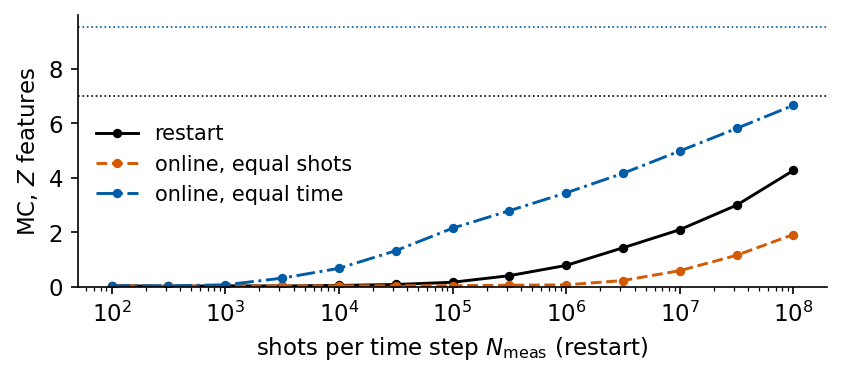

In [27]:
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.4), layout="constrained")
    for (lab, v), st in zip(mc_sh.items(), (dict(color="k", ls="-"), dict(color=DSOrange, ls="--"), dict(color=UJBlue, ls="-."))):
        ax.plot(NMEAS, v, marker="o", ms=3.5, label=lab, **st)
    ax.axhline(mc_inf["restart"], color="k", lw=0.8, ls=":"); ax.axhline(mc_inf["online"], color=UJBlue, lw=0.8, ls=":")
    ax.set_xscale("log"); ax.set_xlabel(r"shots per time step $N_{\rm meas}$ (restart)"); ax.set_ylabel(r"MC, $\hat Z$ features")
    ax.set_ylim(0, None); ax.legend(loc="center left", bbox_to_anchor=(0.0, 0.45), fontsize=10)
    save(fig, "fig_lab047_shots"); plt.show()

With exact expectation values the online protocol at $g=0.3$ has a larger memory capacity, $9.52$, than the restart protocol, $7.00$, as found in the map above. With a finite number of shots the result is dominated by the size of the input-dependent part of the features. Their standard deviation over time is only $4.6\times10^{-4}$ in the restart protocol and $1.6\times10^{-4}$ in the online protocol, so the shot noise has to be smaller than this, which needs millions of shots per step. With $10^6$ restart shots per step the memory capacity is $0.79$, and with $10^8$ it is $4.27$, still below the exact value. At an equal number of shots the online protocol is worse, $1.92$ at $10^8$, because of its larger error per shot and its smaller feature variations. At equal time it collects $1500$ times more shots and is the best of the three, with $3.45$ in the time of $10^6$ restart shots and $6.66$ in the time of $10^8$. In this six-qubit model the statistical cost of estimating the features limits the reservoir more than its dynamics. The model of independent Gaussian errors is a simplification, and these numbers show trends.

<hr/>
## Summary

A register of interacting qubits with one input qubit that is reset at every step forms a reservoir whose state evolves by a linear map on density matrices. The nonlinearity in the input comes from the encoding, and after one step every feature is a combination of $1-s$, $s$ and $\sqrt{s(1-s)}$. Only the linear readout of $63$ Pauli expectation values is trained.

The dynamical regime of the transverse-field Ising network decides whether this works. The level statistics separate chaotic, or ergodic, regions, with $\langle r\rangle$ near the GOE value $0.530$, from the localised and spin-glass regions near the Poisson value $0.388$, and the small registers show a finite-size drop of $\langle r\rangle$ at large field that disappears at $N=10$. In the ergodic regime two copies of the register forget their different initial states exponentially, $D_k\propto e^{-0.118k}$, and the echo state property holds. In the spin-glass and localised regimes they stay apart for hundreds of steps, and a readout trained from one initial state fails from another, with the memory capacity of the spin-glass reservoir falling from $7.95$ to $0.04$. The memory capacity of the six-qubit reservoir peaks at $12.7$ in the ergodic regime near the border of the spin-glass region, at $h=0.063J_s$, and is $0.3$ in the localised regime, which reproduces at small size the trend reported by Martínez-Peña *et al.* for $N=10$. A tuned classical ESN with $63$ neurons reaches $\mathrm{MC}=24.7$ and a higher NARMA-10 score. On the Santa Fe laser the quantum reservoir and the ESN forecast with similar quality, $C_{\rm tot}=24.4$ and $26.5$ over $50$ leads, both far above a linear autoregressive model with $16.4$.

Measurement adds two effects. On average a weak measurement acts as dephasing, which improves the memory capacity at small fields, by up to a factor $1.58$, and reduces it elsewhere, and in equal time the online protocol collects about $K/2$ times more shots than the restart protocol. The features of the six-qubit reservoir vary by only about $10^{-4}$ to $10^{-3}$ over time, so a memory capacity close to the exact one needs more than $10^8$ shots per step in the restart protocol. All results refer to $N=6$ qubits, a few draws of the couplings and exact or Gaussian-noise expectation values. They show how the physics of the reservoir controls its memory. An advantage over a classical reservoir with the same number of features does not appear at this size.

## References

- K. Fujii, K. Nakajima, *Harnessing disordered-ensemble quantum dynamics for machine learning*, Phys. Rev. Appl. **8**, 024030 (2017), [doi:10.1103/PhysRevApplied.8.024030](https://doi.org/10.1103/PhysRevApplied.8.024030)
- R. Martínez-Peña, G. L. Giorgi, J. Nokkala, M. C. Soriano, R. Zambrini, *Dynamical phase transitions in quantum reservoir computing*, Phys. Rev. Lett. **127**, 100502 (2021), [doi:10.1103/PhysRevLett.127.100502](https://doi.org/10.1103/PhysRevLett.127.100502)
- P. Mujal, R. Martínez-Peña, J. Nokkala, J. García-Beni, G. L. Giorgi, M. C. Soriano, R. Zambrini, *Opportunities in quantum reservoir computing and extreme learning machines*, Adv. Quantum Technol. **4**, 2100027 (2021), [doi:10.1002/qute.202100027](https://doi.org/10.1002/qute.202100027)
- P. Mujal, R. Martínez-Peña, G. L. Giorgi, M. C. Soriano, R. Zambrini, *Time-series quantum reservoir computing with weak and projective measurements*, npj Quantum Inf. **9**, 16 (2023), [doi:10.1038/s41534-023-00682-z](https://doi.org/10.1038/s41534-023-00682-z)
- G. Franceschetto, M. Płodzień, M. Lewenstein, A. Acín, P. Mujal, *Harnessing quantum backaction for time-series processing*, Phys. Rev. X **16**, 021002 (2026), [doi:10.1103/j7f9-hfsj](https://doi.org/10.1103/j7f9-hfsj)
- V. Oganesyan, D. A. Huse, *Localization of interacting fermions at high temperature*, Phys. Rev. B **75**, 155111 (2007), [doi:10.1103/PhysRevB.75.155111](https://doi.org/10.1103/PhysRevB.75.155111)
- Y. Y. Atas, E. Bogomolny, O. Giraud, G. Roux, *Distribution of the ratio of consecutive level spacings in random matrix ensembles*, Phys. Rev. Lett. **110**, 084101 (2013), [doi:10.1103/PhysRevLett.110.084101](https://doi.org/10.1103/PhysRevLett.110.084101)
- D. A. Abanin, E. Altman, I. Bloch, M. Serbyn, *Many-body localization, thermalization, and entanglement*, Rev. Mod. Phys. **91**, 021001 (2019), [doi:10.1103/RevModPhys.91.021001](https://doi.org/10.1103/RevModPhys.91.021001)
- H. Jaeger, H. Haas, *Harnessing nonlinearity: predicting chaotic systems and saving energy in wireless communication*, Science **304**, 78 (2004), [doi:10.1126/science.1091277](https://doi.org/10.1126/science.1091277)
- J. Dambre, D. Verstraeten, B. Schrauwen, S. Massar, *Information processing capacity of dynamical systems*, Sci. Rep. **2**, 514 (2012), [doi:10.1038/srep00514](https://doi.org/10.1038/srep00514)
- A. F. Atiya, A. G. Parlos, *New results on recurrent network training: unifying the algorithms and accelerating convergence*, IEEE Trans. Neural Netw. **11**, 697 (2000), [doi:10.1109/72.846741](https://doi.org/10.1109/72.846741)
- A. S. Weigend, N. A. Gershenfeld (eds.), *Time Series Prediction: Forecasting the Future and Understanding the Past*, Addison-Wesley (1994), reprinted by Routledge (2018), [doi:10.4324/9780429492648](https://doi.org/10.4324/9780429492648)